# Lab 5 – “Shout STOP!”: Select a Voice Emergency-Stop Model among Four Lightweight CNNs

Three-class keyword spotter (`stop`, `_unknown_`, `_silence_`) on Google Speech Commands v0.02 for a hands-free voice emergency-stop on a microcontroller. Instead of assuming one architecture is best, this notebook trains **four distinct lightweight CNNs** under an identical protocol, converts each to Float32 and full-INT8 TensorFlow Lite, compares them, and selects one with a **validation-only TinyML rule** (INT8 file under 100 KB, STOP recall and false alarms, macro-F1, then parameters and latency). The held-out test set is used only after the winner is chosen.

**Stages:** Dataset preparation and speaker-wise split → Audio preprocessing and MFCC extraction → Candidate CNN architectures → Fair model training and validation → Architecture comparison and validation-based selection → Final evaluation and INT8 quantisation → Exported artifacts



## 1. Dataset Preparation and Speaker-wise Splitting
Imports, seeds and configuration. The class order `stop, _unknown_, _silence_` is defined once here and used by every model.

In [1]:
import os, json, time, hashlib, random, tarfile, shutil, zipfile
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample_poly, get_window
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
keras.utils.set_random_seed(SEED)                       # seeds python, numpy and tensorflow
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- classes (single source of truth) --------------------------------------
CLASSES = ["stop", "_unknown_", "_silence_"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
STOP, UNKNOWN, SILENCE = CLASS_TO_IDX["stop"], CLASS_TO_IDX["_unknown_"], CLASS_TO_IDX["_silence_"]
SPLITS = ["train", "val", "test"]

# ---- audio / dataset configuration -----------------------------------------
SR = 16000                          # target sample rate (Hz)
CLIP_LEN = SR                       # fixed 1.0 s window = 16,000 samples
SPLIT_FRAC = (0.70, 0.15, 0.15)     # fractions of SPEAKERS per split
UNKNOWN_KEEP_PCT = 10               # keep ~10% of every non-stop word (deterministic hash subset)
SILENCE_RATIO = 0.12                # silence clips = 12% of the speech clips in each split
SILENCE_ZERO_FRAC = 0.20            # share of silence clips that are exact zeros
SIZE_LIMIT_BYTES = 100_000          # 100 KB target, taken conservatively as 100,000 bytes (< 102,400)

DATA_URLS = ["http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz",
             "https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz"]
WORK_DIR = "/content/data"
SUBSET_DIR = os.path.join(WORK_DIR, "speech_subset_unk%dpct" % UNKNOWN_KEEP_PCT)
OUT_DIR = "/content/lab5_outputs"
for d in (WORK_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| NumPy", np.__version__)

TensorFlow 2.21.0 | Keras 3.13.2 | NumPy 2.1.3


In [2]:
def download_dataset():
    errors = []
    for url in DATA_URLS:
        try:
            path = keras.utils.get_file(fname="speech_commands_v0.02.tar.gz", origin=url,
                                        cache_dir=WORK_DIR, cache_subdir="")
            if os.path.getsize(path) > 2_000_000_000:
                return path
            errors.append("%s -> archive smaller than expected (incomplete download?)" % url)
        except Exception as e:
            errors.append("%s -> %s" % (url, e))
            print("Download attempt failed:", errors[-1])
    raise RuntimeError("Could not download Speech Commands v0.02:\n" + "\n".join(errors))

archive_path = download_dataset()
print("Archive:", archive_path, "| %.2f GB" % (os.path.getsize(archive_path) / 1e9))

MARKER = os.path.join(SUBSET_DIR, "_DONE")

def keep_file(word, base):
    if word == "stop":
        return True
    h = int(hashlib.md5((word + "/" + base).encode()).hexdigest(), 16)
    return (h % 100) < UNKNOWN_KEEP_PCT                 # order-independent, reproducible subset

if not os.path.exists(MARKER):
    shutil.rmtree(SUBSET_DIR, ignore_errors=True)
    os.makedirs(SUBSET_DIR)
    try:
        with tarfile.open(archive_path, "r|gz") as tar:  # sequential streaming read
            for m in tar:
                if not m.isfile():
                    continue
                name = m.name[2:] if m.name.startswith("./") else m.name
                parts = name.split("/")
                if len(parts) != 2 or not parts[1].endswith(".wav"):
                    continue
                folder, base = parts
                if folder == "_background_noise_":
                    wanted = True
                elif folder.startswith("_"):
                    wanted = False
                else:
                    wanted = keep_file(folder, base)
                if not wanted:
                    continue
                os.makedirs(os.path.join(SUBSET_DIR, folder), exist_ok=True)
                with open(os.path.join(SUBSET_DIR, folder, base), "wb") as f:
                    f.write(tar.extractfile(m).read())
    except (tarfile.TarError, EOFError, OSError) as e:
        shutil.rmtree(SUBSET_DIR, ignore_errors=True)
        raise RuntimeError("Extraction failed (%s). Delete %s and re-run the download cell." % (e, archive_path)) from e
    with open(MARKER, "w") as f:
        f.write("ok")
else:
    print("Subset already extracted - skipping.")

words = sorted(w for w in os.listdir(SUBSET_DIR) if not w.startswith("_"))
counts = {w: len(os.listdir(os.path.join(SUBSET_DIR, w))) for w in words}
if counts.get("stop", 0) == 0:
    raise ValueError("No STOP recordings found - the positive class would be empty.")
if len(words) < 2 or sum(v for k, v in counts.items() if k != "stop") == 0:
    raise ValueError("No recordings for the _unknown_ class were extracted.")
print("stop clips:", counts["stop"], "| other words:", len(words) - 1,
      "| unknown-pool clips:", sum(v for k, v in counts.items() if k != "stop"))
print("noise files:", sorted(os.listdir(os.path.join(SUBSET_DIR, "_background_noise_"))))

2428923189/2428923189 ━━━━━━━━━━━━━━━━━━━━ 57s 0us/step
Archive: /content/data/speech_commands_v0.02.tar.gz | 2.43 GB
stop clips: 3872 | other words: 34 | unknown-pool clips: 10253
noise files: ['doing_the_dishes.wav', 'dude_miaowing.wav', 'exercise_bike.wav', 'pink_noise.wav', 'running_tap.wav', 'white_noise.wav']


In [3]:
sr_seen, ch_seen, bad_files = Counter(), Counter(), []

def load_wav_mono_16k(path):
    sr, x = wavfile.read(path)
    sr_seen[int(sr)] += 1
    if x.dtype == np.int16:
        x = x.astype(np.float32) / 32768.0
    elif x.dtype == np.int32:
        x = x.astype(np.float32) / 2147483648.0
    elif x.dtype == np.uint8:
        x = (x.astype(np.float32) - 128.0) / 128.0
    else:
        x = x.astype(np.float32)
    ch_seen[1 if x.ndim == 1 else int(x.shape[1])] += 1
    if x.ndim == 2:
        x = x.mean(axis=1)                                   # mono
    if sr != SR:                                             # resample only when necessary
        g = int(np.gcd(int(sr), SR))
        x = resample_poly(x, SR // g, int(sr) // g).astype(np.float32)
    return x.astype(np.float32)

def fix_length(x, n=CLIP_LEN):
    if len(x) < n:
        x = np.pad(x, (0, n - len(x)))                       # zero-pad short clips at the end
    return x[:n]                                             # crop long clips

def to_int16(x):
    return np.clip(np.round(x * 32767.0), -32768, 32767).astype(np.int16)

records, waves_speech = [], []
for word in words:
    label = STOP if word == "stop" else UNKNOWN
    for base in sorted(os.listdir(os.path.join(SUBSET_DIR, word))):
        path = os.path.join(SUBSET_DIR, word, base)
        try:
            x = load_wav_mono_16k(path)
        except (ValueError, OSError) as e:
            bad_files.append((path, str(e)))
            continue
        records.append(dict(file=word + "/" + base, word=word, label=label,
                            speaker=base.split("_nohash_")[0], orig_len=len(x)))
        waves_speech.append(to_int16(fix_length(x)))

print("Loaded speech clips:", len(records), "| unreadable files skipped:", len(bad_files))
for p, e in bad_files[:5]:
    print("  skipped:", p, "->", e)
print("Sample rates seen:", dict(sr_seen), "| channel counts:", dict(ch_seen))
print("Clips shorter than 1 s (zero-padded): %.1f%%" % (100 * np.mean([r["orig_len"] < CLIP_LEN for r in records])))

Loaded speech clips: 14125 | unreadable files skipped: 0
Sample rates seen: {16000: 14125} | channel counts: {1: 14125}
Clips shorter than 1 s (zero-padded): 9.5%


**Speaker-wise split, before any augmentation.** The filename prefix (e.g. `0a2b400e_nohash_3.wav`) is the dataset's anonymised speaker ID. The set of speakers is shuffled with a fixed seed and split 70/15/15, so every recording of a speaker lands in exactly one split. The 2,337 speaker count is taken *before* de-duplication.

**Duplicate recordings.** Byte-identical audio under different filenames is found by content hash and removed; if a duplicate crossed splits, the test copy would be kept, then validation, and the training copy dropped (here no duplicate group crossed splits).

In [4]:
df_speech = pd.DataFrame(records)
speakers = np.array(sorted(df_speech["speaker"].unique()))
perm = np.random.RandomState(SEED).permutation(len(speakers))
n_tr = int(round(SPLIT_FRAC[0] * len(speakers)))
n_va = int(round(SPLIT_FRAC[1] * len(speakers)))
spk_to_split = {}
for rank, k in enumerate(perm):
    spk_to_split[speakers[k]] = "train" if rank < n_tr else ("val" if rank < n_tr + n_va else "test")
df_speech["split"] = df_speech["speaker"].map(spk_to_split)
Wsp = np.stack(waves_speech).astype(np.int16)
del waves_speech
print("Unique speakers:", len(speakers), "->", {s: sum(v == s for v in spk_to_split.values()) for s in SPLITS})

df_speech["hash"] = [hashlib.md5(Wsp[i].tobytes()).hexdigest() for i in range(len(Wsp))]
n_before = len(df_speech)
n_cross_groups = int((df_speech.groupby("hash")["split"].nunique() > 1).sum())

priority = {"test": 0, "val": 1, "train": 2}
ordered = df_speech.assign(_p=df_speech["split"].map(priority)).sort_values("_p", kind="stable")
kept = ordered.drop_duplicates("hash", keep="first")
keep_idx = np.sort(kept.index.values)
df_speech = df_speech.loc[keep_idx].reset_index(drop=True)
Wsp = Wsp[keep_idx]
print("Speech clips before de-duplication: %d | after: %d | removed: %d" % (n_before, len(df_speech), n_before - len(df_speech)))
print("Duplicate groups that crossed splits (resolved): %d" % n_cross_groups)

Unique speakers: 2337 -> {'train': 1636, 'val': 351, 'test': 350}
Speech clips before de-duplication: 14125 | after: 14003 | removed: 122
Duplicate groups that crossed splits (resolved): 0


**`_silence_` construction.** Each silence clip is either exact zeros (20 %) or a random 1 s crop of a background-noise recording scaled by a random gain in [0, 1]. Every noise file is cut by time (first 70 % train, next 15 % validation, last 15 % test), so no noise segment is shared between splits.

In [5]:
noise_dir = os.path.join(SUBSET_DIR, "_background_noise_")
noise = {fn: load_wav_mono_16k(os.path.join(noise_dir, fn))
         for fn in sorted(os.listdir(noise_dir)) if fn.endswith(".wav")}
if not noise:
    raise ValueError("No background-noise files found - cannot build the _silence_ class.")
NOISE_REGION = {"train": (0.00, 0.70), "val": (0.70, 0.85), "test": (0.85, 1.00)}
noise_names = sorted(noise)

rng_sil = np.random.RandomState(SEED + 1)
sil_records, sil_waves = [], []
for split in SPLITS:
    n_speech = int((df_speech["split"] == split).sum())
    n_sil = int(round(SILENCE_RATIO * n_speech))
    for _ in range(n_sil):
        if rng_sil.rand() < SILENCE_ZERO_FRAC:
            clip, kind = np.zeros(CLIP_LEN, np.float32), "zeros"
        else:
            fn = noise_names[rng_sil.randint(len(noise_names))]
            x = noise[fn]
            lo, hi = int(NOISE_REGION[split][0] * len(x)), int(NOISE_REGION[split][1] * len(x))
            start = rng_sil.randint(lo, hi - CLIP_LEN + 1)
            clip, kind = (x[start:start + CLIP_LEN] * rng_sil.uniform(0.0, 1.0)).astype(np.float32), "noise:" + fn
        sil_records.append(dict(file=kind, word="_silence_", label=SILENCE, speaker="n/a", orig_len=CLIP_LEN, split=split))
        sil_waves.append(to_int16(clip))

df = pd.concat([df_speech, pd.DataFrame(sil_records)], ignore_index=True)
W = np.concatenate([Wsp, np.stack(sil_waves)]).astype(np.int16)      # clean int16 waveforms aligned with df
df["label_name"] = df["label"].map(lambda i: CLASSES[i])
assert len(df) == len(W)
del Wsp, sil_waves
print("Total clips:", len(df), "| waveform array:", W.shape, W.dtype, "| %.0f MB" % (W.nbytes / 1e6))

/tmp/ipykernel_3188/4169101913.py:4: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr, x = wavfile.read(path)


Total clips: 15684 | waveform array: (15684, 16000) int16 | 502 MB


**Class balance and leakage checks.** Class counts per split, then explicit checks for shared speakers, filenames and identical audio; any empty class or any overlap raises an error.


In [6]:
dist = pd.crosstab(df["split"], df["label_name"]).reindex(index=SPLITS, columns=CLASSES).fillna(0).astype(int)
dist["total"] = dist[CLASSES].sum(axis=1)
print("Class counts per split:\n", dist, "\n")
print("Class share (%) per split:\n", (dist[CLASSES].div(dist["total"], axis=0) * 100).round(1), "\n")
print("Unknown : stop ratio (train) = %.2f  (class weights compensate in training)" % (dist.loc["train", "_unknown_"] / max(dist.loc["train", "stop"], 1)))
if (dist[CLASSES] == 0).any().any():
    raise ValueError("A class is empty in at least one split:\n%s" % dist)

is_speech = (df["speaker"] != "n/a").values
spk_sets = {s: set(df.loc[is_speech & (df["split"] == s).values, "speaker"]) for s in SPLITS}
file_sets = {s: set(df.loc[is_speech & (df["split"] == s).values, "file"]) for s in SPLITS}
hash_sets = {s: set(df.loc[is_speech & (df["split"] == s).values, "hash"]) for s in SPLITS}
leak_report = {}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    leak_report[a + "-" + b] = {"shared_speakers": len(spk_sets[a] & spk_sets[b]),
                                "shared_files": len(file_sets[a] & file_sets[b]),
                                "shared_audio_hashes": len(hash_sets[a] & hash_sets[b])}
print("Leakage check (every value must be 0):")
for k, v in leak_report.items():
    print("  %-11s %s" % (k, v))
if any(x != 0 for v in leak_report.values() for x in v.values()):
    raise AssertionError("LEAKAGE DETECTED between splits - do not continue.")
print("PASS: speaker-wise split verified; no shared speakers, files or identical recordings.")
print("Silence clips: noise files are cut into disjoint time regions per split, so no noise segment is shared.")

Class counts per split:
 label_name  stop  _unknown_  _silence_  total
split                                        
train       2573       7059       1156  10788
val          569       1513        250   2332
test         641       1648        275   2564 

Class share (%) per split:
 label_name  stop  _unknown_  _silence_
split                                 
train       23.9       65.4       10.7
val         24.4       64.9       10.7
test        25.0       64.3       10.7 

Unknown : stop ratio (train) = 2.74  (class weights compensate in training)
Leakage check (every value must be 0):
  train-val   {'shared_speakers': 0, 'shared_files': 0, 'shared_audio_hashes': 0}
  train-test  {'shared_speakers': 0, 'shared_files': 0, 'shared_audio_hashes': 0}
  val-test    {'shared_speakers': 0, 'shared_files': 0, 'shared_audio_hashes': 0}
PASS: speaker-wise split verified; no shared speakers, files or identical recordings.
Silence clips: noise files are cut into disjoint time regions per split

## 2. Audio Preprocessing and MFCC Extraction
Conventions used for **all** splits, **all** candidate models and at inference: mono, 16 kHz, int16 ÷ 32768 → float32 in [-1, 1] (fixed scale, no per-clip gain normalisation, no pre-emphasis), exactly 16,000 samples. **Training-only** augmentation (one extra copy of each training speech clip: time shift ±100 ms and background noise with p = 0.8, gain 0–0.1) draws noise only from the *training* region of the noise files; validation and test are never augmented.

In [7]:
AUG_SHIFT_MS = 100
AUG_SHIFT = int(SR * AUG_SHIFT_MS / 1000)         # ±1600 samples
AUG_NOISE_P = 0.8
AUG_NOISE_GAIN = (0.0, 0.1)

idx = {s: np.where(df["split"].values == s)[0] for s in SPLITS}
y_all = df["label"].values.astype(np.int64)

# noise pool = TRAIN time-region of every noise file only (validation/test regions are never touched)
lo_f, hi_f = NOISE_REGION["train"]
noise_train = [noise[fn][int(lo_f * len(noise[fn])): int(hi_f * len(noise[fn]))] for fn in noise_names]
assert all(len(n) > CLIP_LEN for n in noise_train)

def augment_clip(x_int16, rng):
    x = x_int16.astype(np.float32) / 32768.0
    shift = rng.randint(-AUG_SHIFT, AUG_SHIFT + 1)                  # small time shift, zero-filled
    if shift > 0:
        x = np.concatenate([np.zeros(shift, np.float32), x[:-shift]])
    elif shift < 0:
        x = np.concatenate([x[-shift:], np.zeros(-shift, np.float32)])
    if rng.rand() < AUG_NOISE_P:                                    # background noise from the train region
        nz = noise_train[rng.randint(len(noise_train))]
        start = rng.randint(0, len(nz) - CLIP_LEN + 1)
        x = x + rng.uniform(*AUG_NOISE_GAIN) * nz[start:start + CLIP_LEN]
    return to_int16(np.clip(x, -1.0, 1.0))

aug_src = idx["train"][y_all[idx["train"]] != SILENCE]              # speech clips of the TRAIN split only
assert set(df.loc[aug_src, "split"]) == {"train"}
rng_aug = np.random.RandomState(SEED + 2)
W_aug = np.stack([augment_clip(W[i], rng_aug) for i in aug_src])
y_aug = y_all[aug_src]
print("Augmented copies (train only):", len(W_aug), "| clean train clips:", len(idx["train"]))
print("Augmentation noise comes from the first %d%% of each noise file; validation/test: no augmentation." % int(hi_f * 100))

Augmented copies (train only): 9632 | clean train clips: 10788
Augmentation noise comes from the first 70% of each noise file; validation/test: no augmentation.


**MFCC:** audio → 1 s window → framing/windowing → STFT → power spectrogram → Mel filter bank → log-Mel → DCT → MFCC, giving the model input `(49, 13, 1)`. The frontend lives **outside** the TFLite models, so a microcontroller must re-implement the same steps and constants. The first cell below defines the TensorFlow frontend, prints the shape chain for one clip and runs the **NumPy parity check** (a plain NumPy re-implementation of what an MCU would run must match TensorFlow, otherwise the notebook stops).

In [8]:
# ---- frontend configuration (single source of truth) -----------------------
FRAME_LEN, FRAME_STEP, FFT_LEN = 512, 320, 512          # 32 ms window, 20 ms hop, 512-point real FFT (no zero-padding)
N_BINS = FFT_LEN // 2 + 1                               # 257 spectrogram bins
N_MEL, F_LO, F_HI = 40, 20.0, 7600.0                    # 40 mel filters, 20-7600 Hz
LOG_EPS = 1e-6                                          # numerical stabiliser inside the log
N_MFCC = 13                                             # keep MFCC c0..c12
N_FRAMES = 1 + (CLIP_LEN - FRAME_LEN) // FRAME_STEP     # 49 frames (no end padding)
INPUT_SHAPE = (N_FRAMES, N_MFCC, 1)

HANN = tf.signal.hann_window(FRAME_LEN, periodic=True)
MEL_W = tf.signal.linear_to_mel_weight_matrix(N_MEL, N_BINS, SR, F_LO, F_HI)      # (257, 40), HTK scale, triangular
MEL_W_NP = MEL_W.numpy().astype(np.float64)
assert MEL_W_NP.shape == (N_BINS, N_MEL) and (MEL_W_NP.sum(axis=0) > 0).all(), "empty mel filter"

def frontend_steps(wave):
    # wave: (batch, 16000) float32 in [-1, 1]; every stage of the chain is explicit
    frames = tf.signal.frame(wave, FRAME_LEN, FRAME_STEP, pad_end=False)          # framing
    windowed = frames * HANN                                                      # windowing (periodic Hann)
    stft = tf.signal.rfft(windowed, fft_length=[FFT_LEN])                         # STFT (complex)
    power = tf.math.square(tf.abs(stft))                                          # power spectrogram |X|^2
    mel = tf.tensordot(power, MEL_W, 1)                                           # Mel filter banks
    log_mel = tf.math.log(mel + LOG_EPS)                                          # log-Mel
    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :N_MFCC]       # DCT-II -> keep 13 MFCCs
    return {"frames": frames, "windowed": windowed, "stft": stft, "power": power,
            "mel": mel, "log_mel": log_mel, "mfcc": mfcc}

@tf.function
def mfcc_tf(wave):
    return frontend_steps(wave)["mfcc"]

def extract_features(w_int16, batch=512):
    out = []
    for i in range(0, len(w_int16), batch):
        wav = tf.constant(w_int16[i:i + batch].astype(np.float32) / 32768.0)
        out.append(mfcc_tf(wav).numpy())
    return np.concatenate(out)[..., np.newaxis].astype(np.float32)

# ---- show the shape chain for one clip --------------------------------------
i0 = int(idx["train"][0])
steps = frontend_steps(tf.constant(W[i0:i0 + 1].astype(np.float32) / 32768.0))
print("audio       :", (CLIP_LEN,))
for k in ["frames", "windowed", "stft", "power", "mel", "log_mel", "mfcc"]:
    print("%-12s: %s" % (k, tuple(steps[k].shape[1:])))
assert tuple(steps["mfcc"].shape[1:]) == (N_FRAMES, N_MFCC)
print("Parameters: %d Hz | frame %d (%.0f ms) | hop %d (%.0f ms) | FFT %d | %d mel %.0f-%.0f Hz | %d MFCC | input %s"
      % (SR, FRAME_LEN, 1000 * FRAME_LEN / SR, FRAME_STEP, 1000 * FRAME_STEP / SR, FFT_LEN, N_MEL, F_LO, F_HI, N_MFCC, INPUT_SHAPE))

HANN_NP = get_window("hann", FRAME_LEN, fftbins=True)                 # periodic Hann
_n, _k = np.arange(N_MEL), np.arange(N_MFCC)[:, None]
DCT_MAT = 2.0 * np.cos(np.pi * _k * (2 * _n + 1) / (2 * N_MEL)) / np.sqrt(2.0 * N_MEL)   # (13, 40) DCT-II, TF scaling

def mfcc_numpy(w_int16):
    x = w_int16.astype(np.float64) / 32768.0
    frames = np.lib.stride_tricks.sliding_window_view(x, FRAME_LEN)[::FRAME_STEP]        # (49, 512)
    spec = np.fft.rfft(frames * HANN_NP, n=FFT_LEN, axis=-1)
    power = spec.real ** 2 + spec.imag ** 2
    log_mel = np.log(power @ MEL_W_NP + LOG_EPS)
    return log_mel @ DCT_MAT.T                                                            # (49, 13)

chk = np.random.RandomState(SEED).choice(len(W), 64, replace=False)
ref_np = np.stack([mfcc_numpy(W[i]) for i in chk])
ref_tf = extract_features(W[chk])[..., 0]
max_abs = float(np.max(np.abs(ref_np - ref_tf)))
FRONTEND_PARITY_OK = bool(np.allclose(ref_np, ref_tf, rtol=1e-3, atol=5e-3))
print("NumPy vs TensorFlow MFCC on 64 clips: max |difference| = %.2e -> parity %s" % (max_abs, "OK" if FRONTEND_PARITY_OK else "FAILED"))
if not FRONTEND_PARITY_OK:
    raise AssertionError("NumPy and TensorFlow frontends disagree (max diff %.3e); check windowing, mel table or DCT scaling." % max_abs)

audio       : (16000,)
frames      : (49, 512)
windowed    : (49, 512)
stft        : (49, 257)
power       : (49, 257)
mel         : (49, 40)
log_mel     : (49, 40)
mfcc        : (49, 13)
Parameters: 16000 Hz | frame 512 (32 ms) | hop 320 (20 ms) | FFT 512 | 40 mel 20-7600 Hz | 13 MFCC | input (49, 13, 1)
NumPy vs TensorFlow MFCC on 64 clips: max |difference| = 2.06e-04 -> parity OK


Extract MFCCs for all clips. **Normalisation:** per-coefficient mean/std are estimated on the *training* features only (clean + augmented) and applied to every split; the MCU must apply the same constants before quantising the input. The next cell plots a STOP waveform, its STFT power spectrogram (dB) and raw MFCC heatmaps for STOP, an unknown word and silence (a noise-based silence clip, because exact zeros give a constant image).

In [9]:
F_clean = extract_features(W)                           # (N, 49, 13, 1) raw MFCCs of clean clips
F_aug = extract_features(W_aug)                         # augmented train copies
F_train_raw = np.concatenate([F_clean[idx["train"]], F_aug])
y_train = np.concatenate([y_all[idx["train"]], y_aug])

feat_mean = F_train_raw.mean(axis=(0, 1, 3))            # shape (13,), TRAIN only
feat_std = F_train_raw.std(axis=(0, 1, 3)) + 1e-6

def normalize(F):
    return ((F - feat_mean.reshape(1, 1, -1, 1)) / feat_std.reshape(1, 1, -1, 1)).astype(np.float32)

X_train = normalize(F_train_raw)
X_val, y_val = normalize(F_clean[idx["val"]]), y_all[idx["val"]]
# X_test / y_test are intentionally NOT prepared here; they are created in Stage 6
# (after the winner is chosen in Stage 5) to prevent any accidental test-set use
# during model selection, threshold setting or architecture comparisons.

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val)]:
    assert X.shape[1:] == INPUT_SHAPE and X.dtype == np.float32 and len(X) == len(y) > 0
    assert np.isfinite(X).all(), "non-finite features in " + name
    print("X_%-5s shape=%s dtype=%s | labels=%s" % (name, X.shape, X.dtype, dict(sorted(Counter(CLASSES[k] for k in y).items()))))
print("Normalisation mean:", np.round(feat_mean, 2))
print("Normalisation std :", np.round(feat_std, 2))


X_train shape=(20420, 49, 13, 1) dtype=float32 | labels={'_silence_': 1156, '_unknown_': 14118, 'stop': 5146}
X_val   shape=(2332, 49, 13, 1) dtype=float32 | labels={'_silence_': 250, '_unknown_': 1513, 'stop': 569}
Normalisation mean: [-4.537e+01  5.910e+00  5.700e-01  7.000e-01 -7.200e-01  2.000e-01
 -3.000e-01 -3.000e-02 -1.400e-01 -2.000e-02 -2.300e-01 -1.400e-01
 -3.500e-01]
Normalisation std : [36.26  9.4   4.71  3.57  3.19  2.53  2.31  1.92  1.74  1.6   1.52  1.41
  1.34]


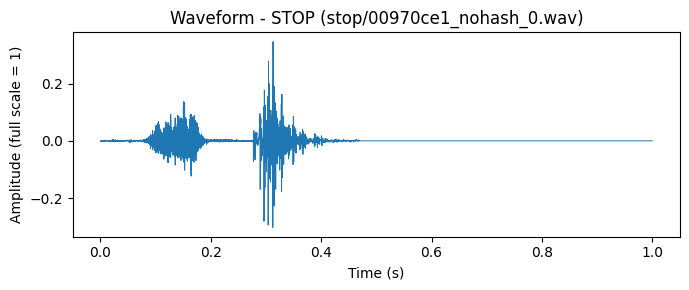

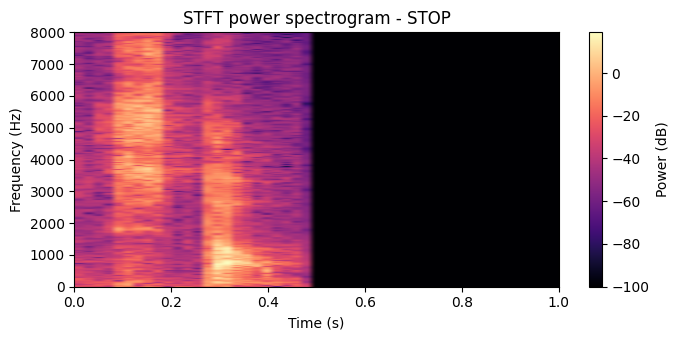

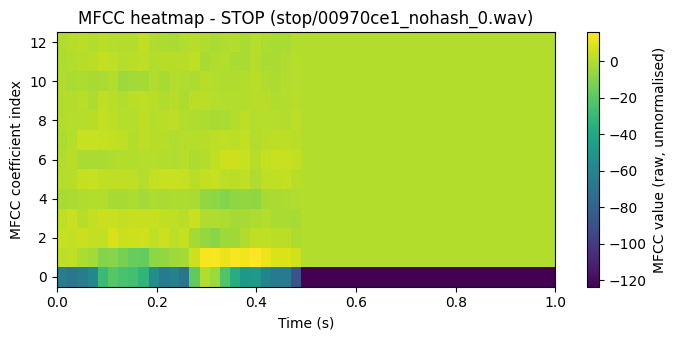

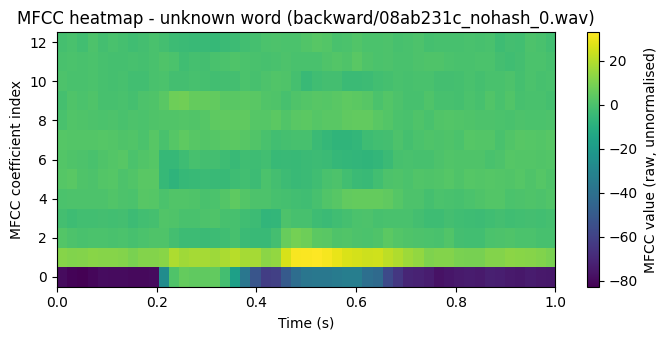

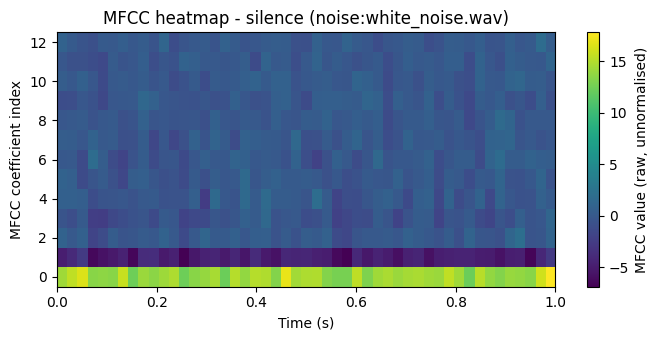

In [10]:
i_stop = int(np.where((df["label"].values == STOP) & (df["split"].values == "train"))[0][0])
i_unk = int(np.where((df["label"].values == UNKNOWN) & (df["split"].values == "train"))[0][0])
i_sil = int(np.where((df["label"].values == SILENCE) & (df["split"].values == "train") & df["file"].str.startswith("noise").values)[0][0])

# 1) waveform
t = np.arange(CLIP_LEN) / SR
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t, W[i_stop].astype(np.float32) / 32768.0, lw=0.7)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Amplitude (full scale = 1)"); ax.set_title("Waveform - STOP (%s)" % df.loc[i_stop, "file"])
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "waveform_stop.png"), dpi=150); plt.show()

# 2) STFT power spectrogram
power = frontend_steps(tf.constant(W[i_stop:i_stop + 1].astype(np.float32) / 32768.0))["power"][0].numpy()
fig, ax = plt.subplots(figsize=(7, 3.5))
im = ax.imshow(10 * np.log10(power.T + 1e-10), origin="lower", aspect="auto", extent=[0, 1, 0, SR / 2], cmap="magma")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Frequency (Hz)"); ax.set_title("STFT power spectrogram - STOP")
fig.colorbar(im, ax=ax, label="Power (dB)")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "stft_spectrogram_stop.png"), dpi=150); plt.show()

# 3) MFCC heatmaps
def plot_mfcc(feat, title, path):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    im = ax.imshow(feat[:, :, 0].T, origin="lower", aspect="auto", extent=[0, 1, -0.5, N_MFCC - 0.5], cmap="viridis")
    ax.set_xlabel("Time (s)"); ax.set_ylabel("MFCC coefficient index"); ax.set_title(title)
    fig.colorbar(im, ax=ax, label="MFCC value (raw, unnormalised)")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

plot_mfcc(F_clean[i_stop], "MFCC heatmap - STOP (%s)" % df.loc[i_stop, "file"], os.path.join(OUT_DIR, "mfcc_stop.png"))
plot_mfcc(F_clean[i_unk], "MFCC heatmap - unknown word (%s)" % df.loc[i_unk, "file"], os.path.join(OUT_DIR, "mfcc_unknown.png"))
plot_mfcc(F_clean[i_sil], "MFCC heatmap - silence (%s)" % df.loc[i_sil, "file"], os.path.join(OUT_DIR, "mfcc_silence.png"))

## 3. Candidate CNN Architectures
Four genuinely different topologies, all taking the identical `(49, 13, 1)` MFCC tensor and ending in global average pooling + 3-way softmax. Each takes a width multiplier `alpha` (channel counts are `base × alpha`, rounded to a multiple of 4); `alpha = 1.0` was chosen for all four so that they land in a similar 20k-parameter range and the comparison is about **topology**, not size.

| Model | Key building block | What makes it different |
|---|---|---|
| **A – Compact Standard CNN** | 3×3 standard convolutions (16-32-64) + BatchNorm + ReLU, 2×2 max-pooling | Dense convolutions and pooling-based downsampling; no depthwise layers |
| **B – DS-CNN** | 10×4 stride-2 stem, then 4 blocks of 3×3 depthwise + 1×1 pointwise (64 ch.) | Depthwise-separable convolution, no skips (the architecture of the previous notebook) |
| **C – Residual DS-CNN** | 3×3 stem (32 ch.), 4 depthwise-separable residual blocks widening 48 → 64 with a stride-2 block | Skip connections: identity where shape and channels match, a 1×1 strided projection where they do not |
| **D – Compact MobileNet-style CNN** | MobileNetV2-style inverted bottlenecks (1×1 expand → 3×3 depthwise → linear 1×1 project, ReLU6) + 1×1 head | Expansion/projection with a linear bottleneck and residual only when stride = 1 and channels match |

The shapes and residual additions are checked at build time (an assertion fails if an `Add` would receive mismatched tensors). Class weights, augmentation and the training loop are identical for all four (Stage 4).

In [11]:
def _w(base, alpha, divisor=4, minimum=8):
    """Width multiplier: round base*alpha to a multiple of `divisor` (at least `minimum`)."""
    return max(minimum, int(base * alpha + divisor / 2) // divisor * divisor)

def _bn_act(x, name, act="relu"):
    x = layers.BatchNormalization(name=name + "_bn")(x)
    if act == "relu":
        x = layers.ReLU(name=name + "_relu")(x)
    elif act == "relu6":
        x = layers.ReLU(max_value=6.0, name=name + "_relu6")(x)
    return x

# ---- Model A: compact standard CNN ------------------------------------------
def build_model_a(input_shape=INPUT_SHAPE, n_classes=3, alpha=1.0, dropout=0.2):
    inp = keras.Input(shape=input_shape, name="mfcc_input")
    x = inp
    for k, base in enumerate((16, 32, 64)):
        x = layers.Conv2D(_w(base, alpha), (3, 3), padding="same", use_bias=False, name="conv%d" % k)(x)
        x = _bn_act(x, "conv%d" % k)
        if k < 2:
            x = layers.MaxPooling2D((2, 2), name="pool%d" % k)(x)              # 49x13 -> 24x6 -> 12x3
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="drop")(x)
    out = layers.Dense(n_classes, activation="softmax", name="softmax")(x)
    return keras.Model(inp, out, name="A_compact_cnn")

# ---- Model B: DS-CNN (same design as the previous notebook) -------------------
def build_model_b(input_shape=INPUT_SHAPE, n_classes=3, alpha=1.0, n_blocks=4, dropout=0.2):
    f = _w(64, alpha)
    inp = keras.Input(shape=input_shape, name="mfcc_input")
    x = layers.Conv2D(f, (10, 4), strides=(2, 2), padding="same", use_bias=False, name="stem_conv")(inp)
    x = _bn_act(x, "stem")
    for b in range(n_blocks):                                                  # depthwise-separable blocks
        x = layers.DepthwiseConv2D((3, 3), padding="same", use_bias=False, name="dw%d" % b)(x)
        x = _bn_act(x, "dw%d" % b)
        x = layers.Conv2D(f, (1, 1), use_bias=False, name="pw%d" % b)(x)
        x = _bn_act(x, "pw%d" % b)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="drop")(x)
    out = layers.Dense(n_classes, activation="softmax", name="softmax")(x)
    return keras.Model(inp, out, name="B_ds_cnn")

# ---- Model C: residual DS-CNN --------------------------------------------------
def _ds_res_block(x, filters, stride, name):
    in_ch = x.shape[-1]
    y = layers.DepthwiseConv2D((3, 3), strides=stride, padding="same", use_bias=False, name=name + "_dw")(x)
    y = _bn_act(y, name + "_dw")
    y = layers.Conv2D(filters, (1, 1), use_bias=False, name=name + "_pw")(y)
    y = layers.BatchNormalization(name=name + "_pw_bn")(y)                     # linear before the addition
    if tuple(stride) == (1, 1) and in_ch == filters:
        shortcut = x                                                           # identity skip
    else:
        shortcut = layers.Conv2D(filters, (1, 1), strides=stride, padding="same", use_bias=False, name=name + "_proj")(x)
        shortcut = layers.BatchNormalization(name=name + "_proj_bn")(shortcut) # projection skip (shape/channels differ)
    assert tuple(y.shape[1:]) == tuple(shortcut.shape[1:]), "residual shape mismatch in %s: %s vs %s" % (name, y.shape, shortcut.shape)
    y = layers.Add(name=name + "_add")([y, shortcut])
    return layers.ReLU(name=name + "_out_relu")(y)

def build_model_c(input_shape=INPUT_SHAPE, n_classes=3, alpha=1.0, dropout=0.2):
    inp = keras.Input(shape=input_shape, name="mfcc_input")
    x = layers.Conv2D(_w(32, alpha), (3, 3), strides=(2, 2), padding="same", use_bias=False, name="stem_conv")(inp)
    x = _bn_act(x, "stem")                                                     # 49x13 -> 25x7
    for k, (base, stride) in enumerate([(48, (1, 1)), (48, (1, 1)), (64, (2, 2)), (64, (1, 1))]):
        x = _ds_res_block(x, _w(base, alpha), stride, "res%d" % k)             # 25x7 ... 13x4
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="drop")(x)
    out = layers.Dense(n_classes, activation="softmax", name="softmax")(x)
    return keras.Model(inp, out, name="C_res_ds_cnn")

# ---- Model D: compact MobileNet-style (inverted bottlenecks) ------------------------
def _inv_bottleneck(x, expansion, out_ch, stride, name):
    in_ch = x.shape[-1]
    y = x
    if expansion != 1:
        y = layers.Conv2D(in_ch * expansion, (1, 1), use_bias=False, name=name + "_exp")(y)
        y = _bn_act(y, name + "_exp", "relu6")
    y = layers.DepthwiseConv2D((3, 3), strides=stride, padding="same", use_bias=False, name=name + "_dw")(y)
    y = _bn_act(y, name + "_dw", "relu6")
    y = layers.Conv2D(out_ch, (1, 1), use_bias=False, name=name + "_proj")(y)
    y = layers.BatchNormalization(name=name + "_proj_bn")(y)                   # linear bottleneck (no activation)
    if tuple(stride) == (1, 1) and in_ch == out_ch:
        assert tuple(x.shape[1:]) == tuple(y.shape[1:]), "residual shape mismatch in " + name
        y = layers.Add(name=name + "_add")([x, y])
    return y

def build_model_d(input_shape=INPUT_SHAPE, n_classes=3, alpha=1.0, dropout=0.2):
    inp = keras.Input(shape=input_shape, name="mfcc_input")
    x = layers.Conv2D(_w(16, alpha), (3, 3), strides=(2, 2), padding="same", use_bias=False, name="stem_conv")(inp)
    x = _bn_act(x, "stem", "relu6")                                            # 49x13 -> 25x7
    for k, (t, base, stride) in enumerate([(2, 24, (1, 1)), (2, 24, (1, 1)), (3, 32, (2, 2)), (3, 32, (1, 1))]):
        x = _inv_bottleneck(x, t, _w(base, alpha), stride, "ib%d" % k)
    x = layers.Conv2D(_w(64, alpha), (1, 1), use_bias=False, name="head_conv")(x)
    x = _bn_act(x, "head", "relu6")
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="drop")(x)
    out = layers.Dense(n_classes, activation="softmax", name="softmax")(x)
    return keras.Model(inp, out, name="D_mobilenet_style")

CANDIDATES = {
    "A_compact_cnn":     dict(label="Model A - Compact Standard CNN",        builder=build_model_a, alpha=1.0),
    "B_ds_cnn":          dict(label="Model B - DS-CNN",                      builder=build_model_b, alpha=1.0),
    "C_res_ds_cnn":      dict(label="Model C - Residual DS-CNN",             builder=build_model_c, alpha=1.0),
    "D_mobilenet_style": dict(label="Model D - Compact MobileNet-style CNN", builder=build_model_d, alpha=1.0),
}

In [12]:
def estimate_macs(model):
    """Approximate multiply-accumulates per inference (Conv2D, DepthwiseConv2D and Dense layers only)."""
    total = 0
    for l in model.layers:
        if isinstance(l, layers.DepthwiseConv2D):
            o, k = l.output.shape, l.kernel_size
            total += o[1] * o[2] * k[0] * k[1] * l.input.shape[-1]
        elif isinstance(l, layers.Conv2D):
            o, k = l.output.shape, l.kernel_size
            total += o[1] * o[2] * k[0] * k[1] * l.input.shape[-1] * l.filters
        elif isinstance(l, layers.Dense):
            total += l.input.shape[-1] * l.units
    return int(total)

arch_rows = []
for name, cfg in CANDIDATES.items():
    keras.backend.clear_session()
    m = cfg["builder"](alpha=cfg["alpha"])
    assert m.input_shape == (None,) + INPUT_SHAPE and m.output_shape == (None, len(CLASSES)), "input/output shape differs from the common contract"
    print("=" * 100, "\n%s  (%s)" % (cfg["label"], name))
    m.summary(line_length=100)
    trainable = int(np.sum([np.prod(v.shape) for v in m.trainable_weights]))
    kinds = Counter(type(l).__name__ for l in m.layers)
    arch_rows.append({"Model": name, "Trainable params": trainable, "Total params": int(m.count_params()),
                      "Approx. MACs": estimate_macs(m), "Conv2D": kinds["Conv2D"], "DepthwiseConv2D": kinds["DepthwiseConv2D"],
                      "Add (skips)": kinds["Add"], "MaxPooling2D": kinds["MaxPooling2D"], "alpha": cfg["alpha"]})
    cfg["trainable_params"], cfg["total_params"], cfg["macs"] = trainable, int(m.count_params()), estimate_macs(m)
arch_df = pd.DataFrame(arch_rows).set_index("Model")
print("\nArchitecture comparison (counts are layer instances; MACs are approximate, conv+dense only):")
print(arch_df.to_string())
assert arch_df.loc["A_compact_cnn", "DepthwiseConv2D"] == 0 and arch_df.loc["B_ds_cnn", "DepthwiseConv2D"] > 0
assert arch_df.loc["C_res_ds_cnn", "Add (skips)"] > 0 and arch_df.loc["D_mobilenet_style", "Add (skips)"] > 0 and arch_df.loc["B_ds_cnn", "Add (skips)"] == 0

Model A - Compact Standard CNN  (A_compact_cnn)


Model: "A_compact_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mfcc_input (InputLayer)                    │ (None, 49, 13, 1)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv0 (Conv2D)                             │ (None, 49, 13, 16)              │               144 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv0_bn (BatchNormalization)              │ (None, 49, 13, 16)              │                64 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv0_relu (ReLU)                          │ (None, 49, 13, 16)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ pool0 (MaxPooling2D)                       │ (None, 24, 6, 16)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv1 (Conv2D)                             │ (None, 24, 6, 32)               │             4,608 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv1_bn (BatchNormalization)              │ (None, 24, 6, 32)               │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv1_relu (ReLU)                          │ (None, 24, 6, 32)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ pool1 (MaxPooling2D)                       │ (None, 12, 3, 32)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2 (Conv2D)                             │ (None, 12, 3, 64)               │            18,432 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2_bn (BatchNormalization)              │ (None, 12, 3, 64)               │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2_relu (ReLU)                          │ (None, 12, 3, 64)               │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ gap (GlobalAveragePooling2D)               │ (None, 64)                      │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ drop (Dropout)                             │ (None, 64)                      │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ softmax (Dense)                            │ (None, 3)                       │               195 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 23,827 (93.07 KB)

 Trainable params: 23,603 (92.20 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ mfcc_input (InputLayer)     │ (None, 49, 13, 1)       │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem_conv (Conv2D)          │ (None, 25, 7, 16)       │            144 │ mfcc_input[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem_bn                     │ (None, 25, 7, 16)       │             64 │ stem_conv[0][0]         │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem_relu6 (ReLU)           │ (None, 25, 7, 16)       │              0 │ stem_bn[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib0_exp (Conv2D)            │ (None, 25, 7, 32)       │            512 │ stem_relu6[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib0_exp_bn                  │ (None, 25, 7, 32)       │            128 │ ib0_exp[0][0]           │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib0_exp_relu6 (ReLU)        │ (None, 25, 7, 32)       │              0 │ ib0_exp_bn[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib0_dw (DepthwiseConv2D)    │ (None, 25, 7, 32)       │            288 │ ib0_exp_relu6[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib0_dw_bn                   │ (None, 25, 7, 32)       │            128 │ ib0_dw[0][0]            │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib0_dw_relu6 (ReLU)         │ (None, 25, 7, 32)       │              0 │ ib0_dw_bn[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib0_proj (Conv2D)           │ (None, 25, 7, 24)       │            768 │ ib0_dw_relu6[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib0_proj_bn                 │ (None, 25, 7, 24)       │             96 │ ib0_proj[0][0]          │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib1_exp (Conv2D)            │ (None, 25, 7, 48)       │          1,152 │ ib0_proj_bn[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib1_exp_bn                  │ (None, 25, 7, 48)       │            192 │ ib1_exp[0][0]           │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib1_exp_relu6 (ReLU)        │ (None, 25, 7, 48)       │              0 │ ib1_exp_bn[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ib1_dw (DepthwiseConv2D)    │ (None, 25, 7, 48)       │            432 │ ib1_exp_relu6[0][0]     │
├─────────────────────────────┼─────────────────────────┼────

 Total params: 21,131 (82.54 KB)

 Trainable params: 19,755 (77.17 KB)

 Non-trainable params: 1,376 (5.38 KB)


Architecture comparison (counts are layer instances; MACs are approximate, conv+dense only):
                   Trainable params  Total params  Approx. MACs  Conv2D  DepthwiseConv2D  Add (skips)  MaxPooling2D  alpha
Model                                                                                                                     
A_compact_cnn                 23603         23827       1419024       3                0            0             2    1.0
B_ds_cnn                      22595         23747       3718592       5                4            0             0    1.0
C_res_ds_cnn                  18947         20067       1702288       7                4            4             0    1.0
D_mobilenet_style             19755         21131       1705408      10                4            2             0    1.0


## 4. Fair Model Training and Validation
Every candidate gets exactly the same treatment: the **same** speaker-wise split, MFCC tensors and class order; the **same** training-only augmented training set (`X_train`, 20,420 clips including the augmented copies); the same class weights (balanced, computed once from the training labels); sparse categorical cross-entropy, Adam (lr 1e-3), batch size 64, at most 30 epochs; `ReduceLROnPlateau` (factor 0.5, patience 3) and `EarlyStopping` (patience 6) both on **validation loss**; the best-validation-loss checkpoint is saved to disk and is the model used from here on. Seed `SEED = 42` is set immediately before each model is built. The test set is never used in this stage.

Limitations that matter for the comparison: GPU training is not bit-reproducible even with a fixed seed, and each architecture is trained once, so small differences between candidates are within run-to-run noise (the selection rule in Stage 5 accounts for this with explicit tolerances). Training time is wall-clock including checkpointing; a one-epoch warm-up on a throw-away model runs first so that one-off GPU start-up cost is not charged to the first candidate.

In [13]:
EPOCHS, BATCH, LR = 30, 64, 1e-3
ES_PATIENCE, LR_PATIENCE = 6, 3
CKPT_DIR = "/content/lab5_candidates"
os.makedirs(CKPT_DIR, exist_ok=True)

cw = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights (shared by all candidates):", {CLASSES[i]: round(w, 3) for i, w in class_weight.items()})
print("Train/val shapes:", X_train.shape, X_val.shape, "| protocol: max %d epochs, batch %d, Adam %.0e, early-stop patience %d on val_loss" % (EPOCHS, BATCH, LR, ES_PATIENCE))

def train_candidate(name):
    cfg = CANDIDATES[name]
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    m = cfg["builder"](alpha=cfg["alpha"])
    m.compile(optimizer=keras.optimizers.Adam(LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    ckpt = os.path.join(CKPT_DIR, name + "_best.keras")
    cbs = [keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, verbose=0),
           keras.callbacks.EarlyStopping(monitor="val_loss", patience=ES_PATIENCE, restore_best_weights=True, verbose=1),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=LR_PATIENCE, min_lr=1e-5, verbose=1)]
    t0 = time.perf_counter()
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS, batch_size=BATCH,
              class_weight=class_weight, callbacks=cbs, verbose=2)
    seconds = time.perf_counter() - t0
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    return dict(history=hist, epochs_run=len(hist["loss"]), best_epoch=int(np.argmin(hist["val_loss"])) + 1,
                best_val_loss=float(min(hist["val_loss"])), max_val_acc_any_epoch=float(max(hist["val_accuracy"])),
                train_seconds=float(seconds), ckpt=ckpt)

# one-epoch warm-up on a throw-away model (not recorded) so GPU/graph start-up is not charged to candidate 1
keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
_w_model = build_model_a(); _w_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
_w_model.fit(X_train[:512], y_train[:512], epochs=1, batch_size=BATCH, verbose=0); del _w_model

train_log = {}
for name, cfg in CANDIDATES.items():
    print("\n" + "=" * 100 + "\nTraining %s (%s) | %d trainable parameters" % (cfg["label"], name, cfg["trainable_params"]))
    train_log[name] = train_candidate(name)
    t = train_log[name]
    print("-> %s: %d epochs, best epoch %d (val_loss %.4f), %.1f s" % (name, t["epochs_run"], t["best_epoch"], t["best_val_loss"], t["train_seconds"]))

Class weights (shared by all candidates): {'stop': 1.323, '_unknown_': 0.482, '_silence_': 5.888}
Train/val shapes: (20420, 49, 13, 1) (2332, 49, 13, 1) | protocol: max 30 epochs, batch 64, Adam 1e-03, early-stop patience 6 on val_loss

Training Model A - Compact Standard CNN (A_compact_cnn) | 23603 trainable parameters
Epoch 1/30
320/320 - 12s - 38ms/step - accuracy: 0.7900 - loss: 0.3725 - val_accuracy: 0.8941 - val_loss: 0.3142 - learning_rate: 0.0010
Epoch 2/30
320/320 - 1s - 5ms/step - accuracy: 0.8961 - loss: 0.1962 - val_accuracy: 0.9288 - val_loss: 0.2006 - learning_rate: 0.0010
Epoch 3/30
320/320 - 1s - 4ms/step - accuracy: 0.9182 - loss: 0.1510 - val_accuracy: 0.8975 - val_loss: 0.2861 - learning_rate: 0.0010
Epoch 4/30
320/320 - 1s - 4ms/step - accuracy: 0.9354 - loss: 0.1235 - val_accuracy: 0.9241 - val_loss: 0.2253 - learning_rate: 0.0010
Epoch 5/30

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
320/320 - 1s - 4ms/step - accuracy: 0.9452 - los

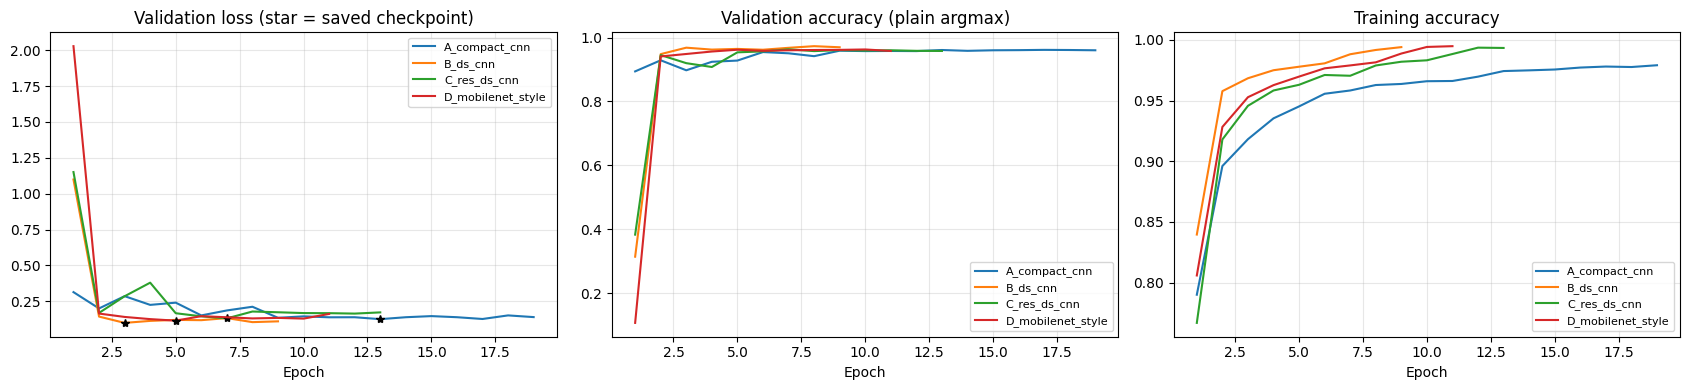

Training summary (validation data only):
                    Trainable params  Epochs run  Best epoch  Best val loss  Max val acc, any epoch (%)  Training time (s)
A_compact_cnn               23603.0        19.0        13.0         0.1259                       96.14               37.5
B_ds_cnn                    22595.0         9.0         3.0         0.0999                       97.30               31.7
C_res_ds_cnn                18947.0        13.0         7.0         0.1313                       96.31               46.8
D_mobilenet_style           19755.0        11.0         5.0         0.1155                       96.27               53.1


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, t in train_log.items():
    h = t["history"]; ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], label=name); axes[1].plot(ep, h["val_accuracy"], label=name)
    axes[2].plot(ep, h["accuracy"], label=name)
    axes[0].plot(t["best_epoch"], t["best_val_loss"], "k*")
axes[0].set_title("Validation loss (star = saved checkpoint)"); axes[1].set_title("Validation accuracy (plain argmax)"); axes[2].set_title("Training accuracy")
for a in axes:
    a.set_xlabel("Epoch"); a.grid(alpha=0.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "training_curves_all_candidates.png"), dpi=150); plt.show()

train_df = pd.DataFrame({n: {"Trainable params": CANDIDATES[n]["trainable_params"], "Epochs run": t["epochs_run"], "Best epoch": t["best_epoch"],
                             "Best val loss": round(t["best_val_loss"], 4), "Max val acc, any epoch (%)": round(100 * t["max_val_acc_any_epoch"], 2),
                             "Training time (s)": round(t["train_seconds"], 1)} for n, t in train_log.items()}).T
print("Training summary (validation data only):\n", train_df.to_string())

## 5. Architecture Comparison and Validation-based Selection

### Selection rule (fixed here, before any test-set result is computed)
Everything in this stage uses **training and validation data only**; `X_test` / `y_test` are not referenced until Stage 6. The model compared is the **deployable full-INT8 TFLite file** of each candidate, evaluated on the validation set.

**Operating point (identical procedure for every candidate).** A clip is `stop` if `p_stop ≥ τ`, otherwise the more likely of the other two classes. τ is chosen per candidate on the **INT8 TFLite validation probabilities** of that candidate: the largest τ on the grid 0.01–0.99 (step 0.01) whose validation STOP recall reaches 98 %, or, if no τ reaches 98 %, the τ with the highest validation STOP recall (largest among ties). Using the INT8 model's own probabilities to set the threshold ensures consistency: the threshold, the selection metrics (Step 1 recall, Step 2 false alarms, Step 3 macro-F1) and the final test evaluation all use the same inference path as the deployed artifact. If INT8 conversion or inference fails for a candidate, the Keras checkpoint probabilities are used as a fallback solely for logging; the candidate is still excluded at Step 0. *This deliberately differs from the previous notebook, whose grid started at 0.05, pinned its τ to the grid edge and derived the threshold from the Keras checkpoint; the wider grid and INT8-derived threshold are applied to all four candidates.*

**Selection steps** (applied in order to the candidates that survive the previous step):
0. **Feasibility:** Float32 and INT8 conversion and inference both succeed, the interpreter confirms int8 input/output and no float32 tensors (and no QUANTIZE/DEQUANTIZE operators where operators can be listed), and the INT8 file is **< 100,000 bytes**. A candidate that fails is excluded and the failure is reported. If no candidate is feasible, **no winner is chosen**.
1. **STOP recall:** keep candidates whose validation STOP recall is within **1 percentage point** of the best feasible candidate.
2. **False alarms:** among those, keep candidates whose validation false-alarm rate (non-STOP clips predicted `stop`) is within **1 percentage point** of the lowest.
3. **Macro-F1:** among those, keep candidates whose validation macro-F1 is within **0.5 percentage point** of the highest.
4. **Tie-break (efficiency):** choose the fewest trainable parameters, then the lower median INT8 latency, then the name (alphabetical, only to make the rule deterministic).

**Why tolerances?** Each architecture is trained once on a GPU that is not bit-reproducible. Re-running the *same* DS-CNN code in the previous notebook moved validation STOP recall from 96.84 % to 97.54 % and test accuracy from 95.79 % to 95.36 %, so differences below about 1 pp should not decide a safety-relevant choice; the tolerances were set before seeing any result and are not tuned. Where a larger or better-recall candidate is excluded by this rule, the notebook prints the trade-off (recall gain versus extra parameters, size and latency) so it can be discussed rather than hidden. Latency is host-CPU time on precomputed MFCC features (not including MFCC extraction) and is not a microcontroller benchmark.

In [15]:
# ---- evaluation helpers shared by every candidate ---------------------------------
TARGET_STOP_RECALL = 0.98
TAU_GRID = np.round(np.arange(0.01, 0.991, 0.01), 2)

def decide(probs, tau):
    pred = 1 + probs[:, 1:].argmax(axis=1)              # best of _unknown_ / _silence_
    pred[probs[:, 0] >= tau] = STOP                      # STOP wins whenever p_stop >= tau
    return pred.astype(np.int64)

def select_tau(probs_val, y_val_):
    rec = np.array([(decide(probs_val, t)[y_val_ == STOP] == STOP).mean() for t in TAU_GRID])
    ok = np.where(rec >= TARGET_STOP_RECALL)[0]
    if len(ok):
        k, met = int(ok.max()), True
        rule = "largest tau on the 0.01-0.99 grid with validation STOP recall >= %.2f" % TARGET_STOP_RECALL
    else:
        k, met = int(np.where(rec == rec.max())[0].max()), False
        rule = "target %.2f unreachable on the 0.01-0.99 grid; tau with the highest validation STOP recall (largest among ties)" % TARGET_STOP_RECALL
    return float(TAU_GRID[k]), rule, met, float(rec[k])

def compute_metrics(y_true, y_pred):
    labels = [0, 1, 2]
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    stop_total, non_stop_total = int((y_true == STOP).sum()), int((y_true != STOP).sum())
    stop_misses = int(((y_true == STOP) & (y_pred != STOP)).sum())
    false_alarms = int(((y_true != STOP) & (y_pred == STOP)).sum())
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(p.mean()), "macro_recall": float(r.mean()),
            "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
            "per_class": {CLASSES[i]: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]), "support": int(s[i])} for i in labels},
            "stop_recall": float(r[0]), "stop_total": stop_total, "stop_misses": stop_misses,
            "stop_miss_rate": float(stop_misses / max(stop_total, 1)),
            "non_stop_total": non_stop_total, "false_alarms": false_alarms,
            "false_alarm_rate": float(false_alarms / max(non_stop_total, 1)),
            "confusion_matrix": cm.tolist()}

def per_class_table(m):
    return pd.DataFrame(m["per_class"]).T[["precision", "recall", "f1", "support"]].round(4)

def plot_confusion(cm, title, path=None, ax=None):
    cm = np.asarray(cm)
    pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(5.8, 5))
    im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES, fontsize=8); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES, fontsize=8)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title, fontsize=9)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, "%d\n(%.1f%%)" % (cm[i, j], 100 * pct[i, j]), ha="center", va="center", color="white" if pct[i, j] > 0.5 else "black", fontsize=8)
    if own:
        fig.colorbar(im, ax=ax, label="Fraction of true class"); fig.tight_layout()
        if path: fig.savefig(path, dpi=150)
        plt.show()

# ---- TFLite conversion, inspection, inference and latency ----------------------------
rep_idx = np.random.RandomState(SEED).choice(len(X_train), size=min(500, len(X_train)), replace=False)
rep_X = X_train[rep_idx]                                   # calibration data: TRAIN split only, identical for every candidate

def convert_float(m):
    return tf.lite.TFLiteConverter.from_keras_model(m).convert()

def convert_int8(m, calib_X):
    conv = tf.lite.TFLiteConverter.from_keras_model(m)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    def rep_gen():
        for i in range(len(calib_X)):
            yield [calib_X[i:i + 1].astype(np.float32)]
    conv.representative_dataset = rep_gen
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8
    conv.inference_output_type = tf.int8
    return conv.convert()                                  # raises if an op cannot be quantised; no float fallback

def inspect_tflite(tfl):
    """Inspect the REAL converted model (not the converter settings)."""
    try:
        interp = tf.lite.Interpreter(model_content=tfl, experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
    except (TypeError, AttributeError):
        interp = tf.lite.Interpreter(model_content=tfl)
    interp.allocate_tensors()
    i_d, o_d = interp.get_input_details()[0], interp.get_output_details()[0]
    tensors = interp.get_tensor_details()
    float_tensors = [t["name"] for t in tensors if t["dtype"] == np.float32]
    try:
        ops = [op["op_name"] for op in interp._get_ops_details()]; ops_ok = True
    except AttributeError:
        ops, ops_ok = None, False
    q_ops = sorted({o for o in (ops or []) if o in ("QUANTIZE", "DEQUANTIZE")})
    int_io = bool(i_d["dtype"] == np.int8 and o_d["dtype"] == np.int8)
    return {"in_dtype": np.dtype(i_d["dtype"]).name, "in_shape": [int(v) for v in i_d["shape"]],
            "in_scale": float(i_d["quantization"][0]), "in_zero_point": int(i_d["quantization"][1]),
            "out_dtype": np.dtype(o_d["dtype"]).name, "out_scale": float(o_d["quantization"][0]), "out_zero_point": int(o_d["quantization"][1]),
            "tensor_dtypes": dict(Counter(np.dtype(t["dtype"]).name for t in tensors)),
            "n_float32_tensors": len(float_tensors), "float32_tensor_examples": float_tensors[:5],
            "operators": dict(Counter(ops)) if ops_ok else None, "operators_verifiable": ops_ok, "quantize_dequantize_ops": q_ops,
            "fully_int8": bool(int_io and not float_tensors and not q_ops)}

def make_runner(tflite_bytes):
    interp = tf.lite.Interpreter(model_content=tflite_bytes, num_threads=1)
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    in_scale, in_zp = inp["quantization"]; out_scale, out_zp = out["quantization"]
    def prep(x):
        if x.dtype == np.int8:
            return x
        if inp["dtype"] == np.int8:
            return np.clip(np.round(x / in_scale + in_zp), -128, 127).astype(np.int8)
        return x.astype(np.float32)
    def run(x):
        interp.set_tensor(inp["index"], prep(x)); interp.invoke()
        y = interp.get_tensor(out["index"])[0]
        if out["dtype"] == np.int8:
            y = (y.astype(np.float32) - out_zp) * out_scale
        return y.astype(np.float32)
    return interp, inp, out, prep, run

def predict_tflite(tflite_bytes, X):
    run = make_runner(tflite_bytes)[4]
    return np.stack([run(X[i:i + 1]) for i in range(len(X))])

def benchmark_latency(tflite_bytes, X, n_samples=200, warmup=20, repeats=5):
    """Per-call invoke() time on precomputed MFCC features (no MFCC extraction), host CPU, 1 thread."""
    interp, inp, out, prep, _ = make_runner(tflite_bytes)
    xs = [prep(X[i:i + 1]) for i in range(min(n_samples, len(X)))]
    for k in range(warmup):
        interp.set_tensor(inp["index"], xs[k % len(xs)]); interp.invoke()
    calls, pass_means = [], []
    for _ in range(repeats):
        times = []
        for x in xs:
            interp.set_tensor(inp["index"], x)
            t0 = time.perf_counter(); interp.invoke(); times.append(time.perf_counter() - t0)
        calls += times; pass_means.append(1000.0 * float(np.mean(times)))
    a = 1000.0 * np.array(calls)
    return {"mean_ms": float(a.mean()), "median_ms": float(np.median(a)), "p95_ms": float(np.percentile(a, 95)),
            "std_of_pass_means_ms": float(np.std(pass_means)), "n_calls": int(len(a)), "warmup_calls": warmup,
            "includes_mfcc_extraction": False}

In [16]:
import traceback
keras_models, cands = {}, {}
for name, cfg in CANDIDATES.items():
    c = dict(name=name, label=cfg["label"], float_tfl=None, int8_tfl=None, float_size=None, int8_size=None,
             float_info=None, int8_info=None, float_error=None, int8_error=None, fully_int8=False, int8_ok=False)
    keras_models[name] = keras.models.load_model(train_log[name]["ckpt"])        # exactly the saved best-validation checkpoint
    try:
        c["float_tfl"] = convert_float(keras_models[name]); c["float_size"] = len(c["float_tfl"]); c["float_info"] = inspect_tflite(c["float_tfl"])
    except Exception as e:
        c["float_tfl"] = None; c["float_error"] = "%s: %s" % (type(e).__name__, str(e)[:400]) + "\n" + traceback.format_exc()[-600:]
    try:
        c["int8_tfl"] = convert_int8(keras_models[name], rep_X); c["int8_size"] = len(c["int8_tfl"]); c["int8_info"] = inspect_tflite(c["int8_tfl"])
        c["fully_int8"] = c["int8_info"]["fully_int8"]; c["int8_ok"] = True
    except Exception as e:
        c["int8_tfl"] = None; c["int8_error"] = "%s: %s" % (type(e).__name__, str(e)[:400]) + "\n" + traceback.format_exc()[-600:]
    cands[name] = c

rows = []
for n, c in cands.items():
    i8 = c["int8_info"] or {}
    rows.append({"Model": n,
                 "Float32 KB": round(c["float_size"] / 1024, 2) if c["float_size"] else "FAILED",
                 "INT8 KB": round(c["int8_size"] / 1024, 2) if c["int8_size"] else "FAILED",
                 "in/out dtype": "%s/%s" % (i8.get("in_dtype"), i8.get("out_dtype")) if i8 else "-",
                 "in scale, zp": "%.5f, %d" % (i8["in_scale"], i8["in_zero_point"]) if i8 else "-",
                 "out scale, zp": "%.5f, %d" % (i8["out_scale"], i8["out_zero_point"]) if i8 else "-",
                 "tensor dtypes": str(i8.get("tensor_dtypes", "-")),
                 "float32 tensors": i8.get("n_float32_tensors", "-"),
                 "Q/DQ ops": i8.get("quantize_dequantize_ops", "-") if i8.get("operators_verifiable") else "not verifiable",
                 "fully INT8": c["fully_int8"]})
print("TFLite conversion and inspection (real interpreter tensor details; representative data = %d TRAIN samples):" % len(rep_X))
print(pd.DataFrame(rows).set_index("Model").to_string())
for n, c in cands.items():
    print("\n%s operators (INT8): %s" % (n, (c["int8_info"] or {}).get("operators", "n/a")))
    for tag in ("float", "int8"):
        if c[tag + "_error"]:
            print("  !! %s conversion FAILED for %s: %s" % (tag.upper(), n, c[tag + "_error"]))

Saved artifact at '/tmp/tmp_z_gn_zi'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 13, 1), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135780163044368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163177744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163177552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163057232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163044752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163176016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163182160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163181968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163182352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163177936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163181584: T

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmpex7755bj'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 13, 1), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135780163044368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163177744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163177552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163057232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163044752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163176016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163182160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163181968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163182352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163177936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780163181584: T

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmp7867poqj'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 13, 1), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135780287875408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287876176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287875984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287876368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287875216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287875600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287877136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287876944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287877328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287875024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780287876560: T

...

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmp7ftarvrn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 13, 1), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135780288198992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288199760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288200336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288199952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288186704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288198416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288198800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288198608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288199184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288199568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135780288200144: T

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


TFLite conversion and inspection (real interpreter tensor details; representative data = 500 TRAIN samples):
                   Float32 KB  INT8 KB in/out dtype in scale, zp  out scale, zp              tensor dtypes  float32 tensors Q/DQ ops  fully INT8
Model                                                                                                                                           
A_compact_cnn           95.68    30.35    int8/int8  0.05389, -3  0.00391, -128   {'int8': 16, 'int32': 8}                0       []        True
B_ds_cnn                93.57    45.25    int8/int8  0.05389, -3  0.00391, -128  {'int8': 24, 'int32': 14}                0       []        True
C_res_ds_cnn            81.91    44.08    int8/int8  0.05389, -3  0.00391, -128  {'int8': 33, 'int32': 16}                0       []        True
D_mobilenet_style       86.82    50.62    int8/int8  0.05389, -3  0.00391, -128  {'int8': 36, 'int32': 19}                0       []        True

A_compact_cnn operat

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [17]:
# ---- threshold selection from INT8 validation predictions -----------------------
# The deployment artifact is the full-INT8 TFLite model, so tau is chosen on the
# INT8 validation probabilities of each candidate rather than on the Keras
# checkpoint probabilities.  This ensures that the frozen threshold is consistent
# with the INT8 quantisation noise and that the metrics used for selection (Step 1
# recall, Step 2 false alarms, Step 3 macro-F1) are all evaluated under the same
# inference path as the deployed model.
#
# Robustness note: prediction/metric calculation and latency benchmarking are in
# separate try/except blocks.  A latency failure therefore cannot mask a successful
# inference run, and a missing latency measurement is recorded explicitly rather
# than silently conflated with an inference failure.
for name, c in cands.items():
    km = keras_models[name]
    probs_k = km.predict(X_val, batch_size=256, verbose=0)
    c["val_acc_argmax_ckpt"] = float((probs_k.argmax(axis=1) == y_val).mean())

    # ---- Step 1: obtain INT8 validation probabilities and select tau ----------
    # INT8 val metrics have NOT been computed yet at this point, so we cannot
    # gate on c.get("val_int8").  Instead we attempt INT8 inference now and
    # derive tau from those probabilities.  On failure the candidate is marked
    # ineligible for selection and tau falls back to Keras-derived only for
    # diagnostic logging – it never makes the candidate eligible.
    if c["int8_tfl"] is not None:
        try:
            probs_int8_for_tau = predict_tflite(c["int8_tfl"], X_val)
            tau_source = "INT8 val predictions"
            # Cache these probabilities so the per-tag loop can reuse them
            # without a second inference call.
            c["_probs_int8_val"] = probs_int8_for_tau
        except Exception as e:
            int8_tau_err = "INT8 tau inference: %s: %s" % (type(e).__name__, str(e)[:300])
            c["int8_error"] = c.get("int8_error", "") + int8_tau_err
            c["int8_ok"] = False
            # Fallback: use Keras probs for tau solely for diagnostic display.
            probs_int8_for_tau = probs_k
            tau_source = "Keras val predictions (INT8 tau inference failed; candidate ineligible)"
            c["_probs_int8_val"] = None   # signal that INT8 inference failed
    else:
        # No INT8 model at all – use Keras probs for tau (diagnostic only).
        probs_int8_for_tau = probs_k
        tau_source = "Keras val predictions (INT8 model unavailable; candidate ineligible)"
        c["_probs_int8_val"] = None

    c["tau"], c["tau_rule"], c["tau_target_met"], c["tau_val_recall"] = select_tau(probs_int8_for_tau, y_val)
    c["tau_source"] = tau_source
    pred_k = decide(probs_k, c["tau"]); c["val_keras"] = compute_metrics(y_val, pred_k)

    for tag in ("float", "int8"):
        c["val_" + tag] = None
        c["lat_" + tag] = None          # initialise explicitly; set only on success
        if c[tag + "_tfl"] is None:
            continue

        # --- pass 1: inference and metrics (independent of latency) ---
        try:
            # For INT8, reuse the probabilities already obtained for tau selection
            # (avoids a redundant second inference run and guarantees consistency).
            if tag == "int8" and c.get("_probs_int8_val") is not None:
                probs = c["_probs_int8_val"]
            else:
                probs = predict_tflite(c[tag + "_tfl"], X_val)
            pred  = decide(probs, c["tau"])
            c["val_" + tag]       = compute_metrics(y_val, pred)
            c["val_agree_" + tag] = float((pred == pred_k).mean())
        except Exception as e:
            err_msg = "inference: %s: %s" % (type(e).__name__, str(e)[:300])
            c[tag + "_error"] = c.get(tag + "_error", "") + err_msg
            if tag == "int8":
                c["int8_ok"] = False
            continue   # no point benchmarking if inference failed

        # --- pass 2: latency (separate try/except; failure recorded, not fatal) ---
        try:
            c["lat_" + tag] = benchmark_latency(c[tag + "_tfl"], X_val)
        except Exception as e:
            lat_err = "latency: %s: %s" % (type(e).__name__, str(e)[:300])
            c[tag + "_error"] = c.get(tag + "_error", "") + " | " + lat_err
            print("  WARNING: latency benchmarking failed for %s (%s): %s" % (name, tag, lat_err))
            # c["lat_" + tag] remains None; handled in Cells 28 and 29.

    # Clean up the temporary cache key before moving to the next candidate.
    c.pop("_probs_int8_val", None)

    print("%-18s tau=%.2f [%s] (%s) | Keras val: acc(argmax) %.4f | tau-rule STOP recall %.4f, false alarms %d%s" % (
        name, c["tau"], tau_source, "target met" if c["tau_target_met"] else "FALLBACK",
        c["val_acc_argmax_ckpt"], c["val_keras"]["stop_recall"], c["val_keras"]["false_alarms"],
        " | INT8 latency: MISSING" if c["lat_int8"] is None and c.get("val_int8") is not None else ""))


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

A_compact_cnn      tau=0.03 [INT8 val predictions] (target met) | Keras val: acc(argmax) 0.9610 | tau-rule STOP recall 0.9824, false alarms 265


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

B_ds_cnn           tau=0.07 [INT8 val predictions] (target met) | Keras val: acc(argmax) 0.9683 | tau-rule STOP recall 0.9789, false alarms 159


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

C_res_ds_cnn       tau=0.01 [INT8 val predictions] (FALLBACK) | Keras val: acc(argmax) 0.9631 | tau-rule STOP recall 0.9701, false alarms 233


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


D_mobilenet_style  tau=0.03 [INT8 val predictions] (target met) | Keras val: acc(argmax) 0.9618 | tau-rule STOP recall 0.9807, false alarms 198


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


VALIDATION comparison (selection evidence; no test data involved):
Model                          A_compact_cnn     B_ds_cnn  C_res_ds_cnn  D_mobilenet_style
Trainable params                   23603.000    22595.000     18947.000          19755.000
Approx. MACs                     1419024.000  3718592.000   1702288.000        1705408.000
Float32 KB                            95.676       93.570        81.906             86.820
INT8 KB                               30.352       45.250        44.078             50.625
Train s                               37.489       31.667        46.776             53.096
Epochs                                19.000        9.000        13.000             11.000
VAL acc Keras ckpt (argmax) %         96.098       96.827        96.312             96.184
VAL max acc any epoch %               96.141       97.298        96.312             96.269
tau                                    0.030        0.070         0.010              0.030
VAL INT8 acc %         

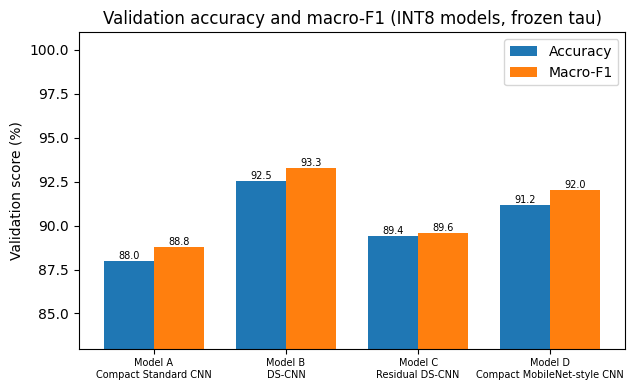

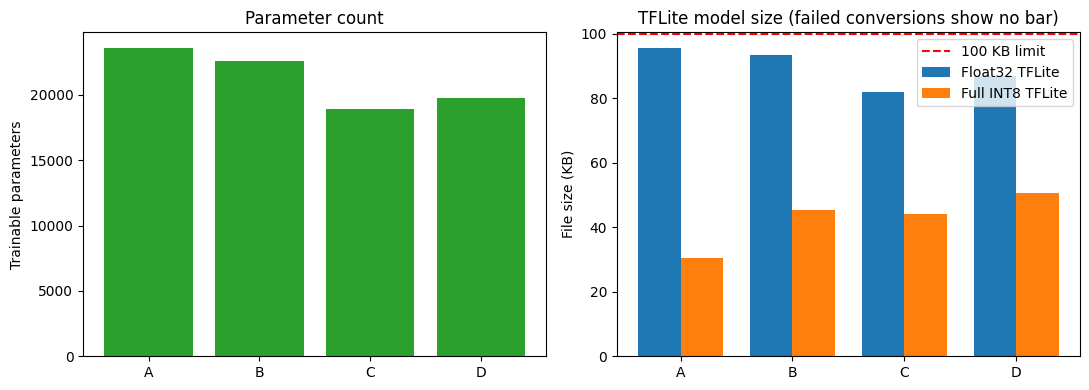

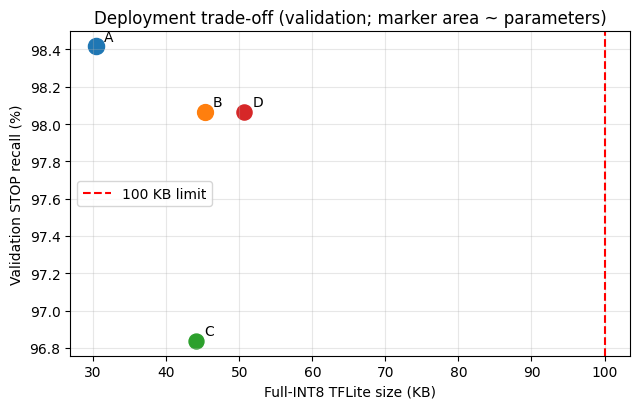

In [18]:
def fmt(v, f="%.2f"):
    return (f % v) if v is not None else "n/a"

val_rows, val_pc_rows = [], []
for n, c in cands.items():
    mi, mf, mk = c.get("val_int8"), c.get("val_float"), c["val_keras"]
    val_rows.append({"Model": n, "Trainable params": CANDIDATES[n]["trainable_params"], "Approx. MACs": CANDIDATES[n]["macs"],
                     "Float32 KB": c["float_size"] / 1024 if c["float_size"] else np.nan, "INT8 KB": c["int8_size"] / 1024 if c["int8_size"] else np.nan,
                     "Train s": train_log[n]["train_seconds"], "Epochs": train_log[n]["epochs_run"],
                     "VAL acc Keras ckpt (argmax) %": 100 * c["val_acc_argmax_ckpt"], "VAL max acc any epoch %": 100 * train_log[n]["max_val_acc_any_epoch"],
                     "tau": c["tau"],
                     "VAL INT8 acc %": 100 * mi["accuracy"] if mi else np.nan, "VAL INT8 macro-F1 %": 100 * mi["macro_f1"] if mi else np.nan,
                     "VAL INT8 STOP recall %": 100 * mi["stop_recall"] if mi else np.nan, "VAL INT8 STOP misses": mi["stop_misses"] if mi else np.nan,
                     "VAL INT8 false alarms": mi["false_alarms"] if mi else np.nan, "VAL INT8 FA rate %": 100 * mi["false_alarm_rate"] if mi else np.nan,
                     "VAL float32 acc %": 100 * mf["accuracy"] if mf else np.nan, "VAL float32 macro-F1 %": 100 * mf["macro_f1"] if mf else np.nan,
                     "Lat float32 mean ms": c["lat_float"]["mean_ms"] if (mf and c.get("lat_float")) else np.nan, "Lat float32 median ms": c["lat_float"]["median_ms"] if (mf and c.get("lat_float")) else np.nan,
                     "Lat INT8 mean ms": c["lat_int8"]["mean_ms"] if (mi and c.get("lat_int8")) else np.nan, "Lat INT8 median ms": c["lat_int8"]["median_ms"] if (mi and c.get("lat_int8")) else np.nan,
                     "Agree float-TFLite vs Keras %": 100 * c["val_agree_float"] if mf else np.nan, "Agree INT8 vs Keras %": 100 * c["val_agree_int8"] if mi else np.nan})
    for tag, m in (("Keras", mk), ("INT8", mi)):
        if m:
            for cls, d in m["per_class"].items():
                val_pc_rows.append({"Model": n, "Split": "validation", "Model type": tag, "Class": cls, "Precision": d["precision"], "Recall": d["recall"], "F1": d["f1"], "Support": d["support"]})
val_table = pd.DataFrame(val_rows).set_index("Model")
val_pc = pd.DataFrame(val_pc_rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
print("VALIDATION comparison (selection evidence; no test data involved):")
print(val_table.round(3).T.to_string())
print("\nVALIDATION per-class precision / recall / F1 (INT8 TFLite at each model's tau):")
print(val_pc[val_pc["Model type"] == "INT8"].drop(columns=["Split", "Model type"]).round(4).to_string(index=False))

ok_names = [n for n in cands if cands[n].get("val_int8")]
short = {n: n.split("_")[0] for n in cands}
# 1) accuracy and macro-F1 (validation, INT8)
fig, ax = plt.subplots(figsize=(6.5, 4)); w, xs = 0.38, np.arange(len(ok_names))
b1 = ax.bar(xs - w / 2, [val_table.loc[n, "VAL INT8 acc %"] for n in ok_names], w, label="Accuracy")
b2 = ax.bar(xs + w / 2, [val_table.loc[n, "VAL INT8 macro-F1 %"] for n in ok_names], w, label="Macro-F1")
ax.set_xticks(xs); ax.set_xticklabels([CANDIDATES[n]["label"].replace(" - ", "\n", 1) for n in ok_names], fontsize=7); ax.set_ylabel("Validation score (%)")
lo = min(val_table.loc[ok_names, ["VAL INT8 acc %", "VAL INT8 macro-F1 %"]].min()) - 5 if ok_names else 0
ax.set_ylim(max(0, lo), 101); ax.set_title("Validation accuracy and macro-F1 (INT8 models, frozen tau)"); ax.legend()
for bars in (b1, b2):
    for r_ in bars: ax.text(r_.get_x() + r_.get_width() / 2, r_.get_height(), "%.1f" % r_.get_height(), ha="center", va="bottom", fontsize=7)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "comparison_val_accuracy_macro_f1.png"), dpi=150); plt.show()
# 2) parameters and model sizes
fig, axes = plt.subplots(1, 2, figsize=(11, 4)); names = list(cands)
axes[0].bar([short[n] for n in names], [CANDIDATES[n]["trainable_params"] for n in names], color="tab:green")
axes[0].set_ylabel("Trainable parameters"); axes[0].set_title("Parameter count")
xs = np.arange(len(names))
axes[1].bar(xs - w / 2, [val_table.loc[n, "Float32 KB"] for n in names], w, label="Float32 TFLite")
axes[1].bar(xs + w / 2, [val_table.loc[n, "INT8 KB"] for n in names], w, label="Full INT8 TFLite")
axes[1].axhline(100, color="red", ls="--", label="100 KB limit"); axes[1].set_xticks(xs); axes[1].set_xticklabels([short[n] for n in names])
axes[1].set_ylabel("File size (KB)"); axes[1].set_title("TFLite model size (failed conversions show no bar)"); axes[1].legend()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "comparison_params_sizes.png"), dpi=150); plt.show()
# 3) deployment trade-off: INT8 size vs validation STOP recall
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for n in ok_names:
    ax.scatter(val_table.loc[n, "INT8 KB"], val_table.loc[n, "VAL INT8 STOP recall %"], s=40 + CANDIDATES[n]["trainable_params"] / 250)
    ax.annotate(short[n], (val_table.loc[n, "INT8 KB"], val_table.loc[n, "VAL INT8 STOP recall %"]), textcoords="offset points", xytext=(6, 4))
ax.axvline(100, color="red", ls="--", label="100 KB limit"); ax.set_xlabel("Full-INT8 TFLite size (KB)"); ax.set_ylabel("Validation STOP recall (%)")
ax.set_title("Deployment trade-off (validation; marker area ~ parameters)"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "comparison_size_vs_stop_recall_val.png"), dpi=150); plt.show()

In [19]:
# ---- apply the pre-declared selection rule (validation data only) ---------------------
D_STOP, D_FA, D_F1 = 0.01, 0.01, 0.005               # tolerances: 1 pp, 1 pp, 0.5 pp (documented before results)
EPS = 1e-12
V = {}
for n, c in cands.items():
    mi, reasons = c.get("val_int8"), []
    if c["float_tfl"] is None or c.get("val_float") is None: reasons.append("Float32 TFLite conversion/inference failed")
    if c["int8_tfl"] is None: reasons.append("INT8 conversion failed")
    elif mi is None: reasons.append("INT8 inference failed")
    else:
        if not c["fully_int8"]: reasons.append("not fully INT8 (float tensors, non-int8 I/O or Q/DQ ops)")
        if c["int8_size"] >= SIZE_LIMIT_BYTES: reasons.append("INT8 file %d bytes >= %d-byte limit" % (c["int8_size"], SIZE_LIMIT_BYTES))
        if c.get("lat_int8") is None: reasons.append("INT8 latency benchmark failed (tie-break latency unavailable)")
    V[n] = dict(reasons=reasons, recall=mi["stop_recall"] if mi else None, fa=mi["false_alarm_rate"] if mi else None,
                f1=mi["macro_f1"] if mi else None, params=CANDIDATES[n]["trainable_params"],
                lat=c["lat_int8"]["median_ms"] if (mi and c.get("lat_int8")) else None, size=c["int8_size"])
status = {n: ("EXCLUDED (step 0): " + "; ".join(V[n]["reasons"])) if V[n]["reasons"] else "feasible" for n in V}
pool = [n for n in V if not V[n]["reasons"]]
decisive = None
if not pool:
    SELECTED = None
else:
    best_r = max(V[n]["recall"] for n in pool); keep = [n for n in pool if V[n]["recall"] >= best_r - D_STOP - EPS]
    for n in pool:
        if n not in keep: status[n] = "dropped at step 1 (STOP recall %.2f%% < best %.2f%% - 1 pp)" % (100 * V[n]["recall"], 100 * best_r)
    pool1 = keep; best_fa = min(V[n]["fa"] for n in pool1); keep = [n for n in pool1 if V[n]["fa"] <= best_fa + D_FA + EPS]
    for n in pool1:
        if n not in keep: status[n] = "dropped at step 2 (false-alarm rate %.2f%% > lowest %.2f%% + 1 pp)" % (100 * V[n]["fa"], 100 * best_fa)
    pool2 = keep; best_f1 = max(V[n]["f1"] for n in pool2); keep = [n for n in pool2 if V[n]["f1"] >= best_f1 - D_F1 - EPS]
    for n in pool2:
        if n not in keep: status[n] = "dropped at step 3 (macro-F1 %.2f%% < best %.2f%% - 0.5 pp)" % (100 * V[n]["f1"], 100 * best_f1)
    # Note: all candidates in `keep` have passed the feasibility check, which now
    # requires lat_int8 to be non-None, so V[n]["lat"] is always a float here.
    pool3 = sorted(keep, key=lambda n: (V[n]["params"], V[n]["lat"] if V[n]["lat"] is not None else float("inf"), n))
    SELECTED = pool3[0]
    for n in pool3[1:]:
        status[n] = "dropped at step 4 (tie-break: more parameters / higher latency than %s)" % SELECTED
    status[SELECTED] = "SELECTED" + (" (sole survivor of step 3)" if len(pool3) == 1 else " (tie-break among %d statistically equivalent candidates)" % len(pool3))

print("SELECTION (validation only; INT8 TFLite models at each model's frozen tau):")
sel_df = pd.DataFrame({"VAL STOP recall %": {n: fmt(100 * V[n]["recall"] if V[n]["recall"] is not None else None) for n in V},
                       "VAL FA rate %": {n: fmt(100 * V[n]["fa"] if V[n]["fa"] is not None else None) for n in V},
                       "VAL macro-F1 %": {n: fmt(100 * V[n]["f1"] if V[n]["f1"] is not None else None) for n in V},
                       "params": {n: V[n]["params"] for n in V}, "INT8 KB": {n: fmt(V[n]["size"] / 1024 if V[n]["size"] else None) for n in V},
                       "median lat ms": {n: fmt(V[n]["lat"], "%.3f") for n in V}, "outcome": status})
print(sel_df.to_string())
if SELECTED is None:
    print("\nNO CANDIDATE satisfies the deployment constraints - no winner is forced. See the exclusion reasons above; Stages 6-7 are intentionally not run.")
else:
    S = cands[SELECTED]
    print("\nSELECTED ARCHITECTURE: %s  [%s]" % (S["label"], SELECTED))
    print("Rule outcome: INT8 %.2f KB (< 100 KB), %d trainable parameters, validation STOP recall %.2f%%, false-alarm rate %.2f%%, macro-F1 %.2f%%, tau = %.2f."
          % (S["int8_size"] / 1024, V[SELECTED]["params"], 100 * V[SELECTED]["recall"], 100 * V[SELECTED]["fa"], 100 * V[SELECTED]["f1"], S["tau"]))
    print("\nTrade-offs versus the selected model (validation, INT8; positive = other model is higher):")
    for n in pool:
        if n == SELECTED: continue
        d_r, d_fa_, d_f1_ = 100 * (V[n]["recall"] - V[SELECTED]["recall"]), 100 * (V[n]["fa"] - V[SELECTED]["fa"]), 100 * (V[n]["f1"] - V[SELECTED]["f1"])
        note = ""
        if d_r > 0 and V[n]["params"] > V[SELECTED]["params"]:
            note = "  <- higher STOP recall (about %d more of %d validation STOP clips) but %+d parameters and %+.1f KB; %s" % (
                round(d_r / 100 * cands[n]["val_int8"]["stop_total"]), cands[n]["val_int8"]["stop_total"], V[n]["params"] - V[SELECTED]["params"],
                (V[n]["size"] - V[SELECTED]["size"]) / 1024, "a gap inside the 1 pp tolerance is not treated as a reliable difference" if d_r <= 100 * D_STOP + 1e-9 else "see the outcome column for why it was not chosen")
        print("  %-18s dSTOP recall %+.2f pp | dFA rate %+.2f pp | dmacro-F1 %+.2f pp | dparams %+d | dINT8 %+.1f KB | dmedian latency %+.3f ms%s" % (
            n, d_r, d_fa_, d_f1_, V[n]["params"] - V[SELECTED]["params"], (V[n]["size"] - V[SELECTED]["size"]) / 1024, V[n]["lat"] - V[SELECTED]["lat"], note))

selection_report = {"rule": {"size_limit_bytes": SIZE_LIMIT_BYTES, "stop_recall_tolerance_pp": 100 * D_STOP, "false_alarm_tolerance_pp": 100 * D_FA,
                             "macro_f1_tolerance_pp": 100 * D_F1, "tie_break": ["fewest trainable parameters", "lower median INT8 latency", "name"],
                             "tau_target_stop_recall": TARGET_STOP_RECALL, "tau_grid": [float(TAU_GRID[0]), float(TAU_GRID[-1]), 0.01],
                             "tau_selection_basis": "INT8 validation predictions (fallback to Keras checkpoint only when INT8 inference failed; such candidates are excluded at Step 0)",
                             "data_used": "training (calibration) and validation only; test set not used", "latency_note": "host CPU, precomputed MFCC input, not an MCU benchmark"},
                    "selected": SELECTED, "selected_label": (cands[SELECTED]["label"] if SELECTED else None), "outcomes": status,
                    "candidates_validation": {n: {k: (None if v is None else v) for k, v in V[n].items()} for n in V}}
val_table.round(4).to_csv(os.path.join(OUT_DIR, "model_comparison_validation.csv"))
with open(os.path.join(OUT_DIR, "selection_report.json"), "w") as f:
    json.dump(selection_report, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

SELECTION (validation only; INT8 TFLite models at each model's frozen tau):
                  VAL STOP recall % VAL FA rate % VAL macro-F1 %  params INT8 KB median lat ms                                                            outcome
A_compact_cnn                 98.42         15.31          88.78   23603   30.35         0.082  dropped at step 2 (false-alarm rate 15.31% > lowest 9.08% + 1 pp)
B_ds_cnn                      98.07          9.08          93.30   22595   45.25         0.299                                 SELECTED (sole survivor of step 3)
C_res_ds_cnn                  96.84         12.88          89.57   18947   44.08         0.110        dropped at step 1 (STOP recall 96.84% < best 98.42% - 1 pp)
D_mobilenet_style             98.07         11.00          92.02   19755   50.62         0.108  dropped at step 2 (false-alarm rate 11.00% > lowest 9.08% + 1 pp)

SELECTED ARCHITECTURE: Model B - DS-CNN  [B_ds_cnn]
Rule outcome: INT8 45.25 KB (< 100 KB), 22595 trainable param

## 6. Final Evaluation and INT8 Quantisation
**Only now is the held-out test set used.** `X_test` and `y_test` are created at the start of this stage from the pre-computed MFCC array `F_clean` and the split index `idx["test"]`; they are intentionally absent from Stage 2 so that no test-set feature enters threshold selection or validation comparisons. The selected architecture (chosen in Stage 5 from validation evidence alone) is evaluated as Keras checkpoint, Float32 TFLite and full-INT8 TFLite on the same test clips under its frozen τ. Afterwards, the other candidates are scored on the test set as a **retrospective benchmark only**: those numbers cannot change the selection, which is already fixed. If Stage 5 found no feasible candidate, the next cell stops on purpose.

“Fully INT8” was verified in Stage 5 from the interpreter (int8 input/output, no float32 tensors, no QUANTIZE/DEQUANTIZE operators where listable), not inferred from `Optimize.DEFAULT`. Latency was measured on 200 **precomputed validation MFCC tensors** (20 warm-up calls, then 5 passes), timing only `invoke()` on the Colab host CPU with one thread: it **excludes MFCC extraction** and is not a microcontroller benchmark.

In [20]:
# ---- guard: skip final evaluation if no candidate qualified -----------------
if SELECTED is None:
    print(
        "NO CANDIDATE satisfied the deployment constraints (see the selection table "
        "above). Stages 6 and 7 are intentionally not run; there is nothing to "
        "evaluate or export. Re-check the feasibility column: typical causes are a "
        "conversion failure, float32 tensors remaining in the INT8 graph, or the "
        "INT8 file exceeding the 100 KB limit."
    )
    # Define sentinel variables so that later cells that reference them do not
    # raise NameError if the user runs them accidentally.
    S = k_sel = TAU = None
    m_keras = m_float = m_int8 = m_keras_argmax = m_float_argmax = m_int8_argmax = None
    probs_k = probs_f = probs_q = pred_k = pred_f = pred_q = None
    agree_kf = agree_kq = agree_fq = None
else:
    # ---- construct the test set (held-out; not used before this point) ----------
    X_test = normalize(F_clean[idx["test"]])
    y_test = y_all[idx["test"]]
    assert X_test.shape[1:] == INPUT_SHAPE and X_test.dtype == np.float32 and len(X_test) == len(y_test) > 0
    assert np.isfinite(X_test).all(), "non-finite features in test set"
    print("X_test  shape=%s dtype=%s | labels=%s" % (X_test.shape, X_test.dtype,
          dict(sorted(Counter(CLASSES[k] for k in y_test).items()))))

    S = cands[SELECTED]; k_sel = keras_models[SELECTED]; TAU = S["tau"]
    print("\nSelected: %s [%s] | frozen tau = %.2f (chosen from %s) | rule: %s\n" % (
        S["label"], SELECTED, TAU, S["tau_source"], S["tau_rule"]))

    probs_k = k_sel.predict(X_test, batch_size=256, verbose=0); pred_k = decide(probs_k, TAU)
    probs_f = predict_tflite(S["float_tfl"], X_test);          pred_f = decide(probs_f, TAU)
    probs_q = predict_tflite(S["int8_tfl"], X_test);           pred_q = decide(probs_q, TAU)
    m_keras, m_float, m_int8 = (compute_metrics(y_test, p) for p in (pred_k, pred_f, pred_q))
    m_keras_argmax, m_float_argmax, m_int8_argmax = (compute_metrics(y_test, p.argmax(axis=1)) for p in (probs_k, probs_f, probs_q))
    agree_kf, agree_kq, agree_fq = float((pred_k == pred_f).mean()), float((pred_k == pred_q).mean()), float((pred_f == pred_q).mean())
    S.update(test_keras=m_keras, test_float=m_float, test_int8=m_int8, test_agree_float=agree_kf, test_agree_int8=agree_kq)

    for tag, m in (("Keras checkpoint", m_keras), ("Float32 TFLite", m_float), ("Full-INT8 TFLite", m_int8)):
        print("TEST - %-17s accuracy %.4f | macro-F1 %.4f | STOP recall %.4f | STOP misses %d/%d | false alarms %d/%d" % (
            tag, m["accuracy"], m["macro_f1"], m["stop_recall"], m["stop_misses"], m["stop_total"], m["false_alarms"], m["non_stop_total"]))
    print("\nPrediction agreement: Keras vs Float32 TFLite %.4f | Keras vs INT8 %.4f | Float32 vs INT8 %.4f" % (agree_kf, agree_kq, agree_fq))
    print("\nPer-class (Float32 TFLite):\n", per_class_table(m_float).to_string())
    print("\nPer-class (Full-INT8 TFLite):\n", per_class_table(m_int8).to_string())
    print("\nReference, plain argmax (no tau): INT8 accuracy %.4f | macro-F1 %.4f | STOP recall %.4f | misses %d | false alarms %d" % (
        m_int8_argmax["accuracy"], m_int8_argmax["macro_f1"], m_int8_argmax["stop_recall"], m_int8_argmax["stop_misses"], m_int8_argmax["false_alarms"]))


X_test  shape=(2564, 49, 13, 1) dtype=float32 | labels={'_silence_': 275, '_unknown_': 1648, 'stop': 641}

Selected: Model B - DS-CNN [B_ds_cnn] | frozen tau = 0.07 (chosen from INT8 val predictions) | rule: largest tau on the 0.01-0.99 grid with validation STOP recall >= 0.98



/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TEST - Keras checkpoint  accuracy 0.9333 | macro-F1 0.9256 | STOP recall 0.9844 | STOP misses 10/641 | false alarms 161/1923
TEST - Float32 TFLite    accuracy 0.9333 | macro-F1 0.9256 | STOP recall 0.9844 | STOP misses 10/641 | false alarms 161/1923
TEST - Full-INT8 TFLite  accuracy 0.9337 | macro-F1 0.9259 | STOP recall 0.9844 | STOP misses 10/641 | false alarms 160/1923

Prediction agreement: Keras vs Float32 TFLite 1.0000 | Keras vs INT8 0.9973 | Float32 vs INT8 0.9973

Per-class (Float32 TFLite):
            precision  recall      f1  support
stop          0.7967  0.9844  0.8807    641.0
_unknown_     0.9935  0.9211  0.9559   1648.0
_silence_     1.0000  0.8873  0.9403    275.0

Per-class (Full-INT8 TFLite):
            precision  recall      f1  support
stop          0.7977  0.9844  0.8813    641.0
_unknown_     0.9935  0.9217  0.9562   1648.0
_silence_     1.0000  0.8873  0.9403    275.0

Reference, plain argmax (no tau): INT8 accuracy 0.9746 | macro-F1 0.9700 | STOP recall 0.964

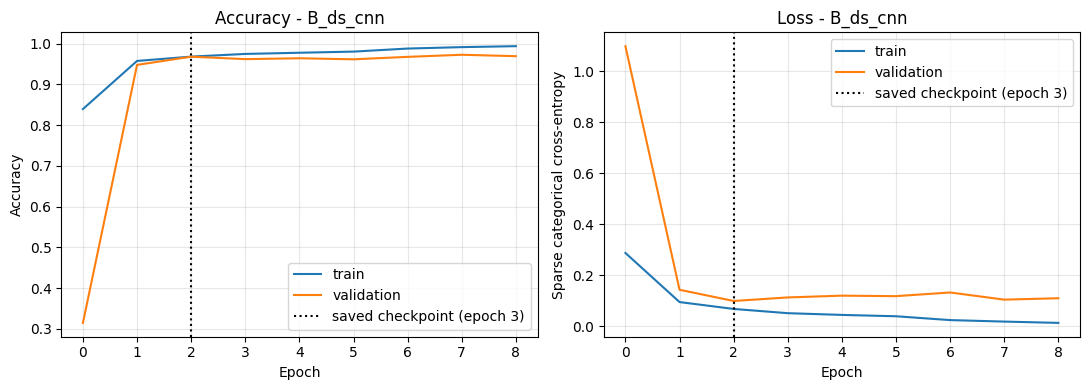

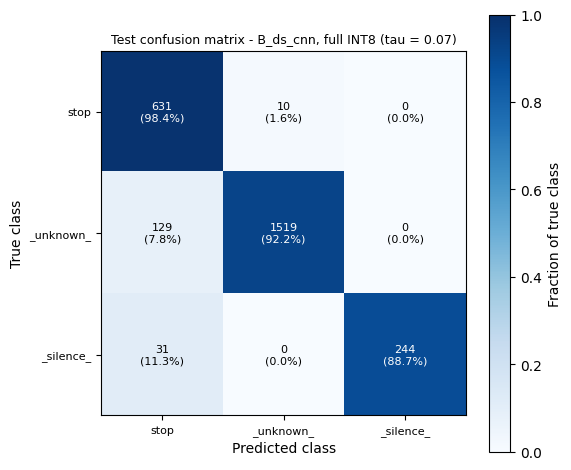

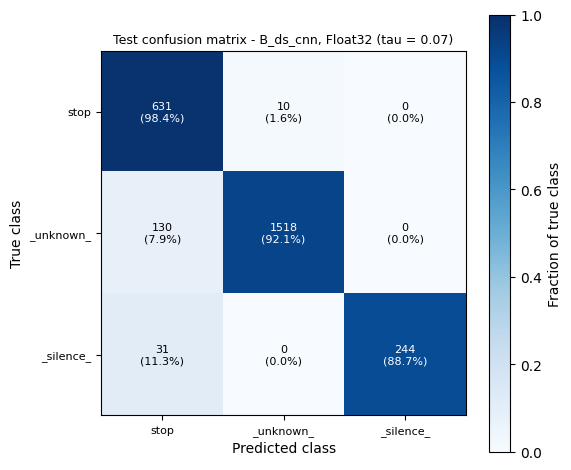

In [21]:
if SELECTED is not None:
    h, tl = train_log[SELECTED]["history"], train_log[SELECTED]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="validation"); axes[0].set_title("Accuracy - %s" % SELECTED)
    axes[1].plot(h["loss"], label="train"); axes[1].plot(h["val_loss"], label="validation"); axes[1].set_title("Loss - %s" % SELECTED)
    for a, yl in zip(axes, ("Accuracy", "Sparse categorical cross-entropy")):
        a.axvline(tl["best_epoch"] - 1, color="k", ls=":", label="saved checkpoint (epoch %d)" % tl["best_epoch"])
        a.set_xlabel("Epoch"); a.set_ylabel(yl); a.legend(); a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=150); plt.show()

    plot_confusion(m_int8["confusion_matrix"], "Test confusion matrix - %s, full INT8 (tau = %.2f)" % (SELECTED, TAU), os.path.join(OUT_DIR, "confusion_matrix.png"))
    plot_confusion(m_float["confusion_matrix"], "Test confusion matrix - %s, Float32 (tau = %.2f)" % (SELECTED, TAU), os.path.join(OUT_DIR, "confusion_matrix_float32.png"))


In [22]:
if SELECTED is not None:
    meta_test = df.iloc[idx["test"]].reset_index(drop=True)

    def examples_table(mask, sort_col, ascending, n=8):
        sel = np.where(mask)[0]
        tab = pd.DataFrame({"file": meta_test["file"].values[sel], "speaker": meta_test["speaker"].values[sel],
                            "true": [CLASSES[k] for k in y_test[sel]], "predicted": [CLASSES[k] for k in pred_q[sel]],
                            "p_stop": probs_q[sel, 0], "p_unknown": probs_q[sel, 1], "p_silence": probs_q[sel, 2]})
        return tab.sort_values(sort_col, ascending=ascending).head(n).round(3)

    miss = (y_test == STOP) & (pred_q != STOP)
    fa = (y_test != STOP) & (pred_q == STOP)
    print("Error analysis of the deployed INT8 model (post-hoc diagnosis only; nothing here feeds back into selection).")
    print("STOP MISSES: %d of %d real STOP clips (miss rate %.2f%%)" % (miss.sum(), (y_test == STOP).sum(), 100 * m_int8["stop_miss_rate"]))
    if miss.sum() > 0:
        print("  missed STOP predicted as:", {k: int(v) for k, v in Counter(CLASSES[k] for k in pred_q[miss]).items()})
        per_spk = meta_test.loc[miss, "speaker"].value_counts()
        print("  misses come from %d different speakers; top speakers: %s" % (len(per_spk), {k: int(v) for k, v in per_spk.head(5).items()}))
        print(examples_table(miss, "p_stop", True).to_string(index=False))
    print("\nSTOP FALSE ALARMS: %d of %d non-STOP clips (false-alarm rate %.2f%%)" % (fa.sum(), (y_test != STOP).sum(), 100 * m_int8["false_alarm_rate"]))
    if fa.sum() > 0:
        print("  false alarms by true class:", {CLASSES[k]: int(v) for k, v in Counter(y_test[fa]).items()})
        fa_words = meta_test.loc[fa, "word"].value_counts(); tot_words = meta_test.loc[y_test != STOP, "word"].value_counts()
        by_word = pd.DataFrame({"false_alarms": fa_words, "test_clips": tot_words}).dropna()
        by_word["rate_%"] = (100 * by_word["false_alarms"] / by_word["test_clips"]).round(1)
        print("\n  words / classes causing most false alarms:\n" + by_word.sort_values("false_alarms", ascending=False).head(8).to_string())
        sil_fa = meta_test.loc[fa & (y_test == SILENCE), "file"]
        if len(sil_fa) > 0:
            print("\n  silence clips raising false alarms, by source:", {k: int(v) for k, v in sil_fa.value_counts().items()})


Error analysis of the deployed INT8 model (post-hoc diagnosis only; nothing here feeds back into selection).
STOP MISSES: 10 of 641 real STOP clips (miss rate 1.56%)
  missed STOP predicted as: {'_unknown_': 10}
  misses come from 9 different speakers; top speakers: {'5b09db89': 2, '0bde966a': 1, '3d86b69a': 1, '40738a2d': 1, '7f208e83': 1}
                      file  speaker true predicted  p_stop  p_unknown  p_silence
stop/3d86b69a_nohash_1.wav 3d86b69a stop _unknown_   0.000      0.996      0.000
stop/5b09db89_nohash_2.wav 5b09db89 stop _unknown_   0.008      0.992      0.000
stop/f250345e_nohash_0.wav f250345e stop _unknown_   0.008      0.992      0.000
stop/0bde966a_nohash_0.wav 0bde966a stop _unknown_   0.012      0.988      0.000
stop/5b09db89_nohash_4.wav 5b09db89 stop _unknown_   0.031      0.965      0.004
stop/7f208e83_nohash_0.wav 7f208e83 stop _unknown_   0.031      0.969      0.000
stop/98ea0818_nohash_4.wav 98ea0818 stop _unknown_   0.031      0.969      0.000
stop/4073

Selected model B_ds_cnn - TEST comparison (same samples, same frozen tau = 0.07):
                                Metric Float32 TFLite Full INT8 TFLite
                       Model size (KB)          93.57            45.25
                     Test accuracy (%)          93.33            93.37
                          Macro-F1 (%)          92.56            92.59
                       STOP recall (%)          98.44            98.44
                           STOP misses             10               10
                     STOP false alarms            161              160
   Agreement with Keras checkpoint (%)         100.00            99.73
  Mean latency (ms, host CPU, no MFCC)          0.109            0.310
Median latency (ms, host CPU, no MFCC)          0.096            0.299

Model-size reduction float -> INT8: 51.6% | Float32 vs INT8 prediction agreement: 99.73%


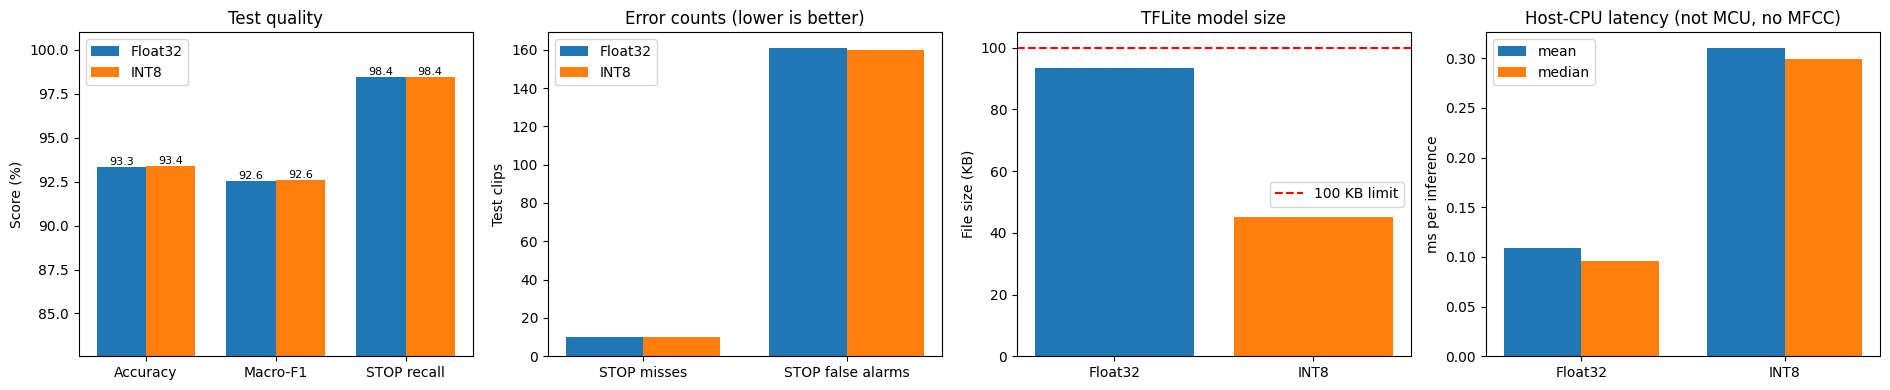

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


MCU-style NumPy frontend + INT8 path vs TF-feature INT8 path on 200 test clips: prediction agreement 1.0000


In [23]:
if SELECTED is not None:
    size_f, size_q = S["float_size"], S["int8_size"]
    lat_f, lat_q = S["lat_float"], S["lat_int8"]
    size_reduction_pct = 100.0 * (1.0 - size_q / size_f)
    rows = [("Model size (KB)", size_f / 1024, size_q / 1024, "%.2f"),
            ("Test accuracy (%)", 100 * m_float["accuracy"], 100 * m_int8["accuracy"], "%.2f"),
            ("Macro-F1 (%)", 100 * m_float["macro_f1"], 100 * m_int8["macro_f1"], "%.2f"),
            ("STOP recall (%)", 100 * m_float["stop_recall"], 100 * m_int8["stop_recall"], "%.2f"),
            ("STOP misses", m_float["stop_misses"], m_int8["stop_misses"], "%d"),
            ("STOP false alarms", m_float["false_alarms"], m_int8["false_alarms"], "%d"),
            ("Agreement with Keras checkpoint (%)", 100 * agree_kf, 100 * agree_kq, "%.2f"),
            ("Mean latency (ms, host CPU, no MFCC)", lat_f["mean_ms"], lat_q["mean_ms"], "%.3f"),
            ("Median latency (ms, host CPU, no MFCC)", lat_f["median_ms"], lat_q["median_ms"], "%.3f")]
    cmp_df = pd.DataFrame({"Metric": [r[0] for r in rows], "Float32 TFLite": [r[3] % r[1] for r in rows], "Full INT8 TFLite": [r[3] % r[2] for r in rows]})
    print("Selected model %s - TEST comparison (same samples, same frozen tau = %.2f):" % (SELECTED, TAU))
    print(cmp_df.to_string(index=False))
    print("\nModel-size reduction float -> INT8: %.1f%% | Float32 vs INT8 prediction agreement: %.2f%%" % (size_reduction_pct, 100 * agree_fq))

    fig, axes = plt.subplots(1, 4, figsize=(19, 4)); w, xs = 0.38, np.arange(3)
    vf = [100 * m_float[k] for k in ("accuracy", "macro_f1", "stop_recall")]; vq = [100 * m_int8[k] for k in ("accuracy", "macro_f1", "stop_recall")]
    b1 = axes[0].bar(xs - w / 2, vf, w, label="Float32"); b2 = axes[0].bar(xs + w / 2, vq, w, label="INT8")
    axes[0].set_xticks(xs); axes[0].set_xticklabels(["Accuracy", "Macro-F1", "STOP recall"]); axes[0].set_ylabel("Score (%)")
    axes[0].set_ylim(max(0.0, min(vf + vq) - 10), 101); axes[0].set_title("Test quality"); axes[0].legend()
    for bars in (b1, b2):
        for r_ in bars: axes[0].text(r_.get_x() + r_.get_width() / 2, r_.get_height(), "%.1f" % r_.get_height(), ha="center", va="bottom", fontsize=8)
    axes[1].bar([0 - w / 2, 1 - w / 2], [m_float["stop_misses"], m_float["false_alarms"]], w, label="Float32")
    axes[1].bar([0 + w / 2, 1 + w / 2], [m_int8["stop_misses"], m_int8["false_alarms"]], w, label="INT8")
    axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["STOP misses", "STOP false alarms"]); axes[1].set_ylabel("Test clips"); axes[1].set_title("Error counts (lower is better)"); axes[1].legend()
    axes[2].bar(["Float32", "INT8"], [size_f / 1024, size_q / 1024], color=["tab:blue", "tab:orange"])
    axes[2].axhline(100, color="red", ls="--", label="100 KB limit"); axes[2].set_ylabel("File size (KB)"); axes[2].set_title("TFLite model size"); axes[2].legend()
    axes[3].bar(np.arange(2) - w / 2, [lat_f["mean_ms"], lat_q["mean_ms"]], w, label="mean"); axes[3].bar(np.arange(2) + w / 2, [lat_f["median_ms"], lat_q["median_ms"]], w, label="median")
    axes[3].set_xticks([0, 1]); axes[3].set_xticklabels(["Float32", "INT8"]); axes[3].set_ylabel("ms per inference"); axes[3].set_title("Host-CPU latency (not MCU, no MFCC)"); axes[3].legend()
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "float_vs_int8.png"), dpi=150); plt.show()

    # ---- end-to-end MCU-style path: NumPy MFCC -> folded normalise+quantise -> INT8 model (200 test clips) ----
    qi = S["int8_info"]; in_scale, in_zp = qi["in_scale"], qi["in_zero_point"]
    fold_a = 1.0 / (feat_std * in_scale)                          # per-coefficient multiplier
    fold_b = in_zp - feat_mean / (feat_std * in_scale)            # per-coefficient offset
    run_q = make_runner(S["int8_tfl"])[4]
    n_e2e = min(200, len(X_test)); W_test = W[idx["test"]]; e2e_probs = []
    for i in range(n_e2e):
        q = np.clip(np.round(mfcc_numpy(W_test[i]) * fold_a + fold_b), -128, 127).astype(np.int8)
        e2e_probs.append(run_q(q.reshape(1, N_FRAMES, N_MFCC, 1)))
    e2e_agree = float((decide(np.stack(e2e_probs), TAU) == pred_q[:n_e2e]).mean())
    print("MCU-style NumPy frontend + INT8 path vs TF-feature INT8 path on %d test clips: prediction agreement %.4f" % (n_e2e, e2e_agree))


### Retrospective test benchmark of all candidates (not used for selection)
The selection above is final. For completeness, every candidate is now scored on the same test set with its own validation-chosen τ, and the validation (selection) and test (retrospective) blocks are shown side by side. Do not read this table as a re-ranking: a candidate that looks better here was not chosen on that basis, and differences of about one percentage point are within the noise of a single training run.

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

Consolidated comparison (selected model: B_ds_cnn):
                                                           A_compact_cnn     B_ds_cnn  C_res_ds_cnn  D_mobilenet_style
DEPLOYMENT / TRAINING           Trainable params               23603.000    22595.000     18947.000          19755.000
                                Approx. MACs                 1419024.000  3718592.000   1702288.000        1705408.000
                                Float32 KB                        95.676       93.570        81.906             86.820
                                INT8 KB                           30.352       45.250        44.078             50.625
                                Train s                           37.489       31.667        46.776             53.096
                                Lat float32 mean ms                0.054        0.109         0.069              0.063
                                Lat float32 median ms              0.049        0.096         0.059              0.

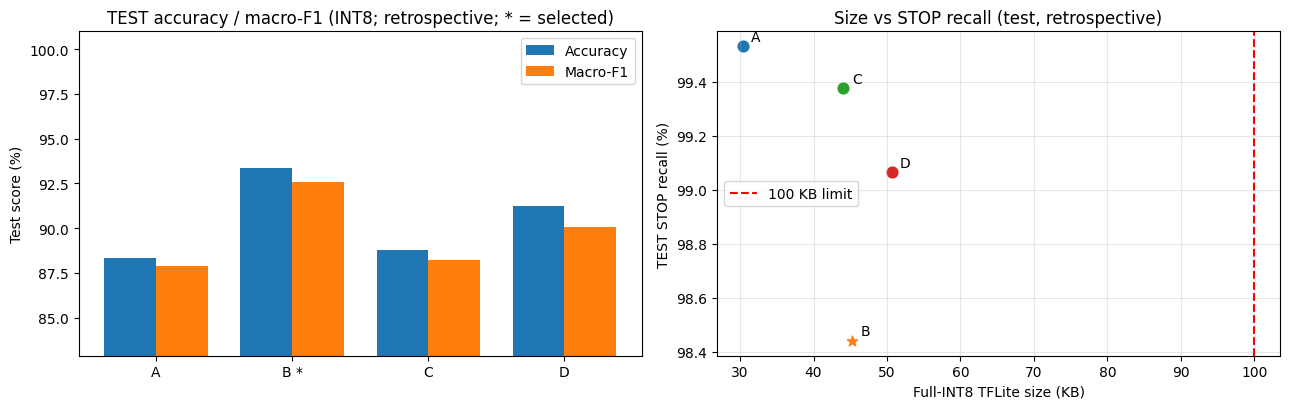

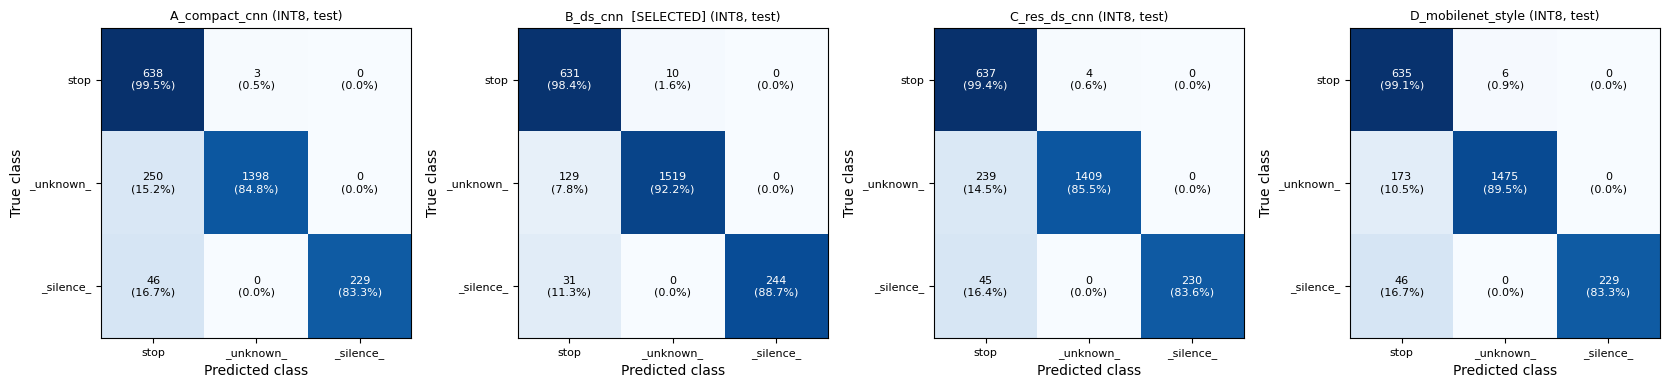

In [24]:
if SELECTED is not None:
    for n, c in cands.items():
        if n == SELECTED:
            continue
        pk = decide(keras_models[n].predict(X_test, batch_size=256, verbose=0), c["tau"]); c["test_keras"] = compute_metrics(y_test, pk)
        for tag in ("float", "int8"):
            c["test_" + tag] = None
            if c[tag + "_tfl"] is None:
                continue
            try:
                pr = decide(predict_tflite(c[tag + "_tfl"], X_test), c["tau"])
                c["test_" + tag] = compute_metrics(y_test, pr); c["test_agree_" + tag] = float((pr == pk).mean())
            except Exception as e:
                c[tag + "_error"] = "test inference: %s: %s" % (type(e).__name__, str(e)[:300])

    def nn(m, k, scale=1.0):
        return scale * m[k] if m else np.nan

    dep_cols = ["Trainable params", "Approx. MACs", "Float32 KB", "INT8 KB", "Train s", "Lat float32 mean ms", "Lat float32 median ms", "Lat INT8 mean ms", "Lat INT8 median ms"]
    val_part = pd.DataFrame({n: {"Keras ckpt acc (argmax) %": 100 * c["val_acc_argmax_ckpt"], "INT8 acc %": nn(c.get("val_int8"), "accuracy", 100),
                                 "INT8 macro-F1 %": nn(c.get("val_int8"), "macro_f1", 100), "INT8 STOP recall %": nn(c.get("val_int8"), "stop_recall", 100),
                                 "INT8 STOP misses": nn(c.get("val_int8"), "stop_misses"), "INT8 false alarms": nn(c.get("val_int8"), "false_alarms"),
                                 "INT8 agree w/ Keras %": 100 * c["val_agree_int8"] if c.get("val_int8") else np.nan} for n, c in cands.items()}).T
    test_part = pd.DataFrame({n: {"Float32 acc %": nn(c.get("test_float"), "accuracy", 100), "Float32 macro-F1 %": nn(c.get("test_float"), "macro_f1", 100),
                                  "INT8 acc %": nn(c.get("test_int8"), "accuracy", 100), "INT8 macro-F1 %": nn(c.get("test_int8"), "macro_f1", 100),
                                  "INT8 STOP recall %": nn(c.get("test_int8"), "stop_recall", 100), "INT8 STOP misses": nn(c.get("test_int8"), "stop_misses"),
                                  "INT8 false alarms": nn(c.get("test_int8"), "false_alarms"),
                                  "Float32 agree w/ Keras %": 100 * c["test_agree_float"] if c.get("test_float") else np.nan,
                                  "INT8 agree w/ Keras %": 100 * c["test_agree_int8"] if c.get("test_int8") else np.nan} for n, c in cands.items()}).T
    cons = pd.concat({"DEPLOYMENT / TRAINING": val_table[dep_cols], "VALIDATION (used for selection)": val_part, "TEST (retrospective, not used)": test_part}, axis=1)
    print("Consolidated comparison (selected model: %s):" % SELECTED)
    print(cons.round(3).T.to_string())

    pc_rows = []
    for n, c in cands.items():
        for split, key in (("validation", "val_int8"), ("test", "test_int8"), ("validation", "val_float"), ("test", "test_float")):
            m = c.get(key)
            if m:
                for cls, d in m["per_class"].items():
                    pc_rows.append({"Model": n, "Split": split, "Model type": "INT8" if "int8" in key else "Float32", "Class": cls, "Precision": d["precision"], "Recall": d["recall"], "F1": d["f1"], "Support": d["support"]})
    pc_all = pd.DataFrame(pc_rows)
    print("\nPer-class precision / recall / F1, INT8 TFLite (validation and test):")
    print(pc_all[pc_all["Model type"] == "INT8"].drop(columns="Model type").round(4).to_string(index=False))
    cons.round(4).to_csv(os.path.join(OUT_DIR, "model_comparison_consolidated.csv")); test_part.round(4).to_csv(os.path.join(OUT_DIR, "model_comparison_test_retrospective.csv"))
    pc_all.round(4).to_csv(os.path.join(OUT_DIR, "model_comparison_per_class.csv"))

    ok_t = [n for n in cands if cands[n].get("test_int8")]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2)); w, xs = 0.38, np.arange(len(ok_t))
    axes[0].bar(xs - w / 2, [test_part.loc[n, "INT8 acc %"] for n in ok_t], w, label="Accuracy"); axes[0].bar(xs + w / 2, [test_part.loc[n, "INT8 macro-F1 %"] for n in ok_t], w, label="Macro-F1")
    axes[0].set_xticks(xs); axes[0].set_xticklabels([n.split("_")[0] + (" *" if n == SELECTED else "") for n in ok_t]); axes[0].set_ylabel("Test score (%)")
    axes[0].set_ylim(max(0, min(test_part.loc[ok_t, ["INT8 acc %", "INT8 macro-F1 %"]].min()) - 5), 101); axes[0].set_title("TEST accuracy / macro-F1 (INT8; retrospective; * = selected)"); axes[0].legend()
    for n in ok_t:
        axes[1].scatter(val_table.loc[n, "INT8 KB"], test_part.loc[n, "INT8 STOP recall %"], s=60, marker="*" if n == SELECTED else "o")
        axes[1].annotate(n.split("_")[0], (val_table.loc[n, "INT8 KB"], test_part.loc[n, "INT8 STOP recall %"]), textcoords="offset points", xytext=(6, 4))
    axes[1].axvline(100, color="red", ls="--", label="100 KB limit"); axes[1].set_xlabel("Full-INT8 TFLite size (KB)"); axes[1].set_ylabel("TEST STOP recall (%)")
    axes[1].set_title("Size vs STOP recall (test, retrospective)"); axes[1].grid(alpha=0.3); axes[1].legend()
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "retrospective_test_comparison.png"), dpi=150); plt.show()

    fig, axes = plt.subplots(1, len(ok_t), figsize=(4.2 * len(ok_t), 4))
    axes = np.atleast_1d(axes)
    for a, n in zip(axes, ok_t):
        plot_confusion(cands[n]["test_int8"]["confusion_matrix"], "%s%s (INT8, test)" % (n, "  [SELECTED]" if n == SELECTED else ""), ax=a)
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "confusion_matrices_all_candidates_test.png"), dpi=150); plt.show()


## 7. Exported Artifacts, Conclusion and Viva Questions
Export the selected model (Keras checkpoint, Float32 TFLite, full-INT8 TFLite) under descriptive names, the class mapping (frontend constants, normalisation, INT8 quantisation parameters, MCU fold constants), the evaluation results and the selection report (rule, tolerances, outcome for every candidate, original model name), plus the comparison tables and plots. Then verify the required files exist, re-check the real INT8 size, build the ZIP of the winner's deployment artifacts and comparison reports, and trigger the Colab download. The other candidates' checkpoints stay in `/content/lab5_candidates` and are not zipped.

In [25]:
if SELECTED is not None:
    to_json = lambda o: o.item() if hasattr(o, "item") else str(o)
    shutil.copy(train_log[SELECTED]["ckpt"], os.path.join(OUT_DIR, "selected_model.keras"))
    with open(os.path.join(OUT_DIR, "selected_model_float32.tflite"), "wb") as f: f.write(S["float_tfl"])
    with open(os.path.join(OUT_DIR, "selected_model_int8.tflite"), "wb") as f: f.write(S["int8_tfl"])

    class_mapping = {
        "selected_model": {"name": SELECTED, "label": S["label"], "trainable_params": CANDIDATES[SELECTED]["trainable_params"], "alpha": CANDIDATES[SELECTED]["alpha"]},
        "classes": CLASSES, "index_to_class": {str(i): c for i, c in enumerate(CLASSES)}, "class_to_index": CLASS_TO_IDX,
        "feature_shape": list(INPUT_SHAPE), "feature_dtype": "float32 (int8 after input quantisation)",
        "frontend": {"sample_rate_hz": SR, "clip_samples": CLIP_LEN, "pcm_scaling": "int16 / 32768, no per-clip normalisation, no pre-emphasis",
                     "frame_length": FRAME_LEN, "frame_step": FRAME_STEP, "window": "hann (periodic)", "fft_length": FFT_LEN,
                     "spectrogram": "power |X|^2", "mel_bins": N_MEL, "mel_range_hz": [F_LO, F_HI], "mel_scale": "HTK, triangular (tf.signal.linear_to_mel_weight_matrix)",
                     "log": "ln(mel + %g)" % LOG_EPS, "dct": "DCT-II, scaled by 1/sqrt(2*N_mel) as tf.signal.mfccs_from_log_mel_spectrograms",
                     "num_mfcc": N_MFCC, "num_frames": N_FRAMES,
                     "normalisation_mean_per_coeff": feat_mean.tolist(), "normalisation_std_per_coeff": feat_std.tolist(),
                     "numpy_tf_parity_max_abs_diff": max_abs,
                     "note": "MFCC extraction is NOT inside the .tflite files; the MCU must implement exactly these steps and constants."},
        "int8_input": {"dtype": qi["in_dtype"], "scale": qi["in_scale"], "zero_point": qi["in_zero_point"]},
        "int8_output": {"dtype": qi["out_dtype"], "scale": qi["out_scale"], "zero_point": qi["out_zero_point"]},
        "mcu_input_fold": {"formula": "q = clip(round(mfcc * a + b), -128, 127) per coefficient", "a": fold_a.tolist(), "b": fold_b.tolist()},
        "decision_rule": {"stop_threshold_tau": TAU, "rule": S["tau_rule"], "selected_on": "validation set only", "target_met_on_validation": S["tau_target_met"],
                          "logic": "predict stop if p_stop >= tau, else argmax of [_unknown_, _silence_]"},
    }
    with open(os.path.join(OUT_DIR, "class_mapping.json"), "w") as f: json.dump(class_mapping, f, indent=2, default=to_json)

    SKIP = {"float_tfl", "int8_tfl"}
    cand_json = {}
    for n, c in cands.items():
        d = {k: v for k, v in c.items() if k not in SKIP}
        d["architecture"] = {k: CANDIDATES[n][k] for k in ("label", "alpha", "trainable_params", "total_params", "macs")}
        d["training"] = {k: v for k, v in train_log[n].items() if k != "history"}
        d["training"]["history"] = train_log[n]["history"]
        cand_json[n] = d
    results = {
        "seed": SEED, "task": "3-class voice emergency-stop keyword detector (Google Speech Commands v0.02)",
        "dataset": {"name": "Google Speech Commands v0.02", "unknown_keep_percent": UNKNOWN_KEEP_PCT, "silence_ratio": SILENCE_RATIO, "silence_zero_fraction": SILENCE_ZERO_FRAC,
                    "n_speakers_before_dedup": int(len(speakers)), "speakers_per_split": {s: len(spk_sets[s]) for s in SPLITS},
                    "class_distribution": {s: {c: int(dist.loc[s, c]) for c in CLASSES} for s in SPLITS},
                    "duplicates_removed": int(n_before - len(df_speech)), "leakage_check": leak_report},
        "preprocessing": {"augmentation": {"train_only": True, "copies": 1, "time_shift_ms": AUG_SHIFT_MS, "noise_probability": AUG_NOISE_P,
                                           "noise_gain_range": list(AUG_NOISE_GAIN), "noise_source": "train time-region of noise files only", "augmented_clips": int(len(W_aug))}},
        "training_protocol": {"epochs_max": EPOCHS, "batch": BATCH, "optimizer": "Adam", "lr": LR, "early_stopping_patience": ES_PATIENCE, "reduce_lr_patience": LR_PATIENCE,
                              "monitor": "val_loss", "class_weight": {CLASSES[i]: w for i, w in class_weight.items()}, "seed": SEED,
                              "caveat": "single run per architecture; GPU training not bit-reproducible"},
        "selection": selection_report, "selected_model_name": SELECTED, "selected_model_label": S["label"],
        "candidates": cand_json,
        "final_test_selected": {"keras": m_keras, "float32_tflite": m_float, "int8_tflite": m_int8, "int8_argmax_reference": m_int8_argmax,
                                "prediction_agreement": {"keras_vs_float32": agree_kf, "keras_vs_int8": agree_kq, "float32_vs_int8": agree_fq, "mcu_style_numpy_path_vs_tf_int8": e2e_agree}},
        "model_sizes_bytes": {"float32_tflite": int(size_f), "int8_tflite": int(size_q)}, "size_reduction_percent": size_reduction_pct,
        "latency_host_cpu_ms": {"float32": lat_f, "int8": lat_q, "measured_on": "first 200 validation MFCC tensors",
                                "note": "Colab host CPU, 1 thread, precomputed MFCC (MFCC extraction NOT included); not microcontroller latency."},
        "quantisation": {"input": class_mapping["int8_input"], "output": class_mapping["int8_output"], "inspection": S["int8_info"],
                         "representative_samples": int(len(rep_X)), "representative_source": "training split only"},
        "int8_under_100KB": bool(size_q < SIZE_LIMIT_BYTES),
    }
    with open(os.path.join(OUT_DIR, "evaluation_results.json"), "w") as f: json.dump(results, f, indent=2, default=to_json)

    REQUIRED = ["selected_model.keras", "selected_model_float32.tflite", "selected_model_int8.tflite", "training_curves.png", "training_curves_all_candidates.png",
                "mfcc_stop.png", "mfcc_unknown.png", "mfcc_silence.png", "confusion_matrix.png", "float_vs_int8.png",
                "comparison_val_accuracy_macro_f1.png", "comparison_params_sizes.png", "comparison_size_vs_stop_recall_val.png",
                "retrospective_test_comparison.png", "confusion_matrices_all_candidates_test.png",
                "model_comparison_validation.csv", "model_comparison_test_retrospective.csv", "model_comparison_consolidated.csv", "model_comparison_per_class.csv",
                "selection_report.json", "evaluation_results.json", "class_mapping.json"]
    print("Artifacts in %s:" % OUT_DIR)
    for fn in sorted(os.listdir(OUT_DIR)):
        s = os.path.getsize(os.path.join(OUT_DIR, fn))
        print("  %-42s %10d bytes (%9.2f KB)%s" % (fn, s, s / 1024, "" if fn in REQUIRED else "   [extra]"))
    missing = [fn for fn in REQUIRED if not os.path.exists(os.path.join(OUT_DIR, fn))]
    if missing:
        raise FileNotFoundError("Missing required artifacts: %s" % missing)
    print("\nAll %d required files are present. Selected architecture: %s [%s]" % (len(REQUIRED), S["label"], SELECTED))
    final_int8 = os.path.getsize(os.path.join(OUT_DIR, "selected_model_int8.tflite"))
    print("Actual INT8 model size: %d bytes = %.2f KB" % (final_int8, final_int8 / 1024))
    if final_int8 >= SIZE_LIMIT_BYTES:
        raise RuntimeError("INT8 model is %d bytes - NOT under 100 KB." % final_int8)
    print("PASS: INT8 model is under 100 KB (< %d bytes) | fully INT8 (int8 I/O, no float32 tensors, no Q/DQ ops): %s" % (SIZE_LIMIT_BYTES, S["fully_int8"]))

    zip_path = shutil.make_archive("/content/lab5_stop_artifacts", "zip", OUT_DIR)
    with zipfile.ZipFile(zip_path) as z:
        print("\nZIP created: %s | %.1f KB | %d files" % (zip_path, os.path.getsize(zip_path) / 1024, len(z.namelist())))
    try:
        from google.colab import files
    except ImportError:
        print("google.colab is not available here (not running in Colab). Download the ZIP manually from:", zip_path)
    else:
        files.download(zip_path)


Artifacts in /content/lab5_outputs:
  class_mapping.json                               3346 bytes (     3.27 KB)
  comparison_params_sizes.png                     49166 bytes (    48.01 KB)
  comparison_size_vs_stop_recall_val.png          53112 bytes (    51.87 KB)
  comparison_val_accuracy_macro_f1.png            51161 bytes (    49.96 KB)
  confusion_matrices_all_candidates_test.png      98262 bytes (    95.96 KB)
  confusion_matrix.png                            58732 bytes (    57.36 KB)
  confusion_matrix_float32.png                    58647 bytes (    57.27 KB)   [extra]
  evaluation_results.json                         67835 bytes (    66.25 KB)
  float_vs_int8.png                               94735 bytes (    92.51 KB)
  mfcc_silence.png                                42110 bytes (    41.12 KB)
  mfcc_stop.png                                   47128 bytes (    46.02 KB)
  mfcc_unknown.png                                48223 bytes (    47.09 KB)
  model_comparison_consolidate

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
if SELECTED is not None:
    from IPython.display import display, Markdown

    d_acc, d_f1 = 100 * (m_int8["accuracy"] - m_float["accuracy"]), 100 * (m_int8["macro_f1"] - m_float["macro_f1"])
    d_rec, d_miss, d_fa = 100 * (m_int8["stop_recall"] - m_float["stop_recall"]), m_int8["stop_misses"] - m_float["stop_misses"], m_int8["false_alarms"] - m_float["false_alarms"]
    n_feasible = sum(1 for n in V if not V[n]["reasons"])
    tie_txt = status[SELECTED][len("SELECTED "):]
    rank_f1 = 1 + sum(1 for n in ok_t if test_part.loc[n, "INT8 macro-F1 %"] > test_part.loc[SELECTED, "INT8 macro-F1 %"] + 1e-9)
    better_test = [n for n in ok_t if test_part.loc[n, "INT8 macro-F1 %"] > test_part.loc[SELECTED, "INT8 macro-F1 %"] + 1.0]
    retro = ("On the retrospective test benchmark the selected model ranks %d of %d by INT8 test macro-F1%s." % (
        rank_f1, len(ok_t), "; %s scored more than 1 pp higher, but selection was fixed on validation evidence and a single run per architecture cannot separate differences of that size reliably" % ", ".join(better_test) if better_test else ""))
    faster = "INT8 was slower" if lat_q["median_ms"] > lat_f["median_ms"] else "INT8 was faster"
    miss_note = ("INT8 had %d fewer STOP miss(es) but %+d false alarms; such a small difference is specific to this test set and does not show INT8 is safer." % (-d_miss, d_fa)
                 if d_miss < 0 else "INT8 had %+d STOP misses and %+d false alarms; differences this small are specific to this test set." % (d_miss, d_fa))
    display(Markdown(f"""
    ### Conclusion (computed from this run)
    * **Selection:** {n_feasible} of {len(cands)} candidates met the deployment constraints (full-INT8, < {SIZE_LIMIT_BYTES:,} bytes). Using the validation-only rule, **{S['label']}** (`{SELECTED}`) was chosen {tie_txt}. On validation it reached STOP recall {100*V[SELECTED]['recall']:.2f}%, false-alarm rate {100*V[SELECTED]['fa']:.2f}% and macro-F1 {100*V[SELECTED]['f1']:.2f}% with {V[SELECTED]['params']:,} trainable parameters (tau = {TAU:.2f}). Trade-offs against the other candidates are printed in Stage 5.
    * **Size:** the INT8 model is **{size_q/1024:.2f} KB** ({size_q:,} bytes), which {'meets' if size_q < SIZE_LIMIT_BYTES else 'does NOT meet'} the 100 KB limit; it is **{size_reduction_pct:.1f}%** smaller than the Float32 TFLite file ({size_f/1024:.2f} KB) and {'is' if S['fully_int8'] else 'is NOT'} fully integer (int8 input/output, no float32 tensors).
    * **Final test results (INT8):** accuracy {100*m_int8['accuracy']:.2f}% ({d_acc:+.2f} pp vs Float32), macro-F1 {100*m_int8['macro_f1']:.2f}% ({d_f1:+.2f} pp), STOP recall {100*m_int8['stop_recall']:.2f}% ({d_rec:+.2f} pp) with {m_int8['stop_misses']} of {m_int8['stop_total']} STOP clips missed and {m_int8['false_alarms']} false alarms among {m_int8['non_stop_total']} non-STOP clips. {miss_note} Float32/INT8 prediction agreement {100*agree_fq:.2f}%; INT8 agreement with the Keras checkpoint {100*agree_kq:.2f}%.
    * **Retrospective benchmark:** {retro}
    * **Latency:** median {lat_f['median_ms']:.3f} ms (Float32) vs {lat_q['median_ms']:.3f} ms (INT8): {faster} on this host. If INT8 is slower, a likely cause is that host float kernels are better optimised than the int8 path on x86 (not profiled here); the INT8 benefit is memory and integer-only MCU execution. These timings use **precomputed MFCC input**, **exclude MFCC extraction** and are **not a microcontroller benchmark**.
    * **Deployment:** MFCC extraction is not embedded in the TFLite models; the device must implement the frontend and the normalisation/quantisation constants in `class_mapping.json`.
    * **Limits of this study:** one training run per architecture, so small differences are within noise; a classroom-scale model on read-speech data and **not a certified industrial safety system**.
    """))



    ### Conclusion (computed from this run)
    * **Selection:** 4 of 4 candidates met the deployment constraints (full-INT8, < 100,000 bytes). Using the validation-only rule, **Model B - DS-CNN** (`B_ds_cnn`) was chosen (sole survivor of step 3). On validation it reached STOP recall 98.07%, false-alarm rate 9.08% and macro-F1 93.30% with 22,595 trainable parameters (tau = 0.07). Trade-offs against the other candidates are printed in Stage 5.
    * **Size:** the INT8 model is **45.25 KB** (46,336 bytes), which meets the 100 KB limit; it is **51.6%** smaller than the Float32 TFLite file (93.57 KB) and is fully integer (int8 input/output, no float32 tensors).
    * **Final test results (INT8):** accuracy 93.37% (+0.04 pp vs Float32), macro-F1 92.59% (+0.03 pp), STOP recall 98.44% (+0.00 pp) with 10 of 641 STOP clips missed and 160 false alarms among 1923 non-STOP clips. INT8 had +0 STOP misses and -1 false alarms; differences this small are specific to this test set. Float32/INT8 prediction agreement 99.73%; INT8 agreement with the Keras checkpoint 99.73%.
    * **Retrospective benchmark:** On the retrospective test benchmark the selected model ranks 1 of 4 by INT8 test macro-F1.
    * **Latency:** median 0.096 ms (Float32) vs 0.299 ms (INT8): INT8 was slower on this host. If INT8 is slower, a likely cause is that host float kernels are better optimised than the int8 path on x86 (not profiled here); the INT8 benefit is memory and integer-only MCU execution. These timings use **precomputed MFCC input**, **exclude MFCC extraction** and are **not a microcontroller benchmark**.
    * **Deployment:** MFCC extraction is not embedded in the TFLite models; the device must implement the frontend and the normalisation/quantisation constants in `class_mapping.json`.
    * **Limits of this study:** one training run per architecture, so small differences are within noise; a classroom-scale model on read-speech data and **not a certified industrial safety system**.
    